# 09 · ETF 20종 Peer 상대 변동성 급변 구간 정의 (W4)

**「국내 상장 ETF 20종의 자기 과거 대비 고변동성(A)과 Peer 대비 양방향 상대 변동성 괴리(B)의 17개 노출 그룹 완전 동시 충족으로 정의한 기술적 급변 구간」**

- 연구 ID `t18_peer_relative_shock_w4`, 프로토콜 `W4-lock-1`, 기준 커밋 `534a122` (W3 최종).
- 계약: `research/peer_relative_shock_w4/W4_RESEARCH_CONTRACT.md`, Peer 매핑 계약 `PEER_MAPPING_CONTRACT.md`. 둘 다 **변동성을 한 번도 계산하기 전에** 커밋했다 (`52f98b0`).
- 이 노트북의 목적은 급변 구간을 **반드시 만들어 내는 것이 아니다**. 미리 정한 정의가 실제 20종에서 어떤 상태를 만드는지 정직하게 계산하는 것이다.
- 이 라벨은 기술적 상태 라벨이다. 통계적으로 입증된 구조변화, 미래 급등 정답, 매매 신호가 아니다.

## 0. 실행 환경·동결 지문

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t18_peer_shock_w4_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·캡션
import platform  # Python 버전

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단 (□ 로 그리지 않는다)
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# W2·W3 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화

from r2h.peer_shock import pipeline as P  # W4 계산 파이프라인
from r2h.peer_shock.figures import W4Figures  # W4 그림 (나눔고딕 등록 포함)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/peer_relative_shock_w4"  # W4 산출물 폴더
RES = BASE / "results"  # 집계 결과 (Git 포함)
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)


def preview(path, width=1600):  # 노트북 용량을 줄이는 축소 미리보기 (원본 PNG·SVG 는 figures/ 에 그대로)
    from io import BytesIO  # 메모리 버퍼
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1600px 이하로 축소
    buf = BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


# 계약·설정·Peer 매핑 동결 지문을 대조한다 (결과를 본 뒤 규칙을 바꾸지 않았음을 확인).
for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines():  # 동결 기록 4줄
    digest, name = line.split(maxsplit=1)  # 해시·경로
    assert sha(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 변경되면 중단
# 이전 연구(W1·W2·W3·T12·노트북 00–08) 보호 파일이 그대로인지 확인한다.
PROTECTED = list(csv.DictReader(open(ROOT / "research/joint_cusum_w3/W3_PROTECTED_SHA256.csv", encoding="utf-8")))  # W3 가 남긴 보호 목록
CHANGED = [r["path"] for r in PROTECTED if sha(ROOT / r["path"]) != r["sha256"]]  # 바뀐 보호 파일
assert not CHANGED, f"보호 파일 변경: {CHANGED}"  # 기존 연구는 읽기만
# 원자료 20종 + Peer 참조 해시를 기록과 대조한다.
SRC = json.loads((BASE / "evidence/source_hashes.json").read_text())  # Peer 동결 시점 원자료 지문
BAD = [t for k, d in (("eval_raw", "data/raw"), ("peer_raw", "data/external/peer")) for t, v in SRC[k].items() if sha(ROOT / d / f"{t}.csv") != v["sha256"]]  # 다른 파일
assert not BAD, f"원자료 변경: {BAD}"  # 같은 원자료로만 계산
print("작업트리:", ROOT)  # 실행 위치
print("보호 파일", len(PROTECTED), "개 불변 · 원자료", len(SRC["eval_raw"]), "+ Peer", len(SRC["peer_raw"]), "개 해시 일치")  # 검증 요약
print("실행 환경:", ACTUAL_ENV)  # 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1018/R2H_W4_Peer_Shock
보호 파일 252 개 불변 · 원자료 20 + Peer 51 개 해시 일치
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 0.1 전체 계산 실행 (동결 설정 그대로)

In [2]:
# 동결 설정 그대로 전체 계산을 실행한다: 원자료 → σ → A·B → 17 그룹 → 17/17 → FINAL → 구간 → 진단·민감도·W2/W3 대조.
R = P.run(ROOT)  # 결과표는 results/, 가격 역산 가능한 일별 표는 outputs/t18/ (Git 제외)
CFG, M = R["cfg"], R["main"]  # 설정과 주 정의 결과
FG = W4Figures(R, ROOT)  # 그림 생성기 (같은 결과 객체 사용)
CAP = {}  # 그림별 캡션 수치
print("프로토콜:", CFG["protocol_version"], "| 거래일", R["final"]["calendar"])  # 실행 정보
print("Peer 참조 ETF:", R["final"]["n_peer_tickers"], "종 | 판정:", M["verdict"]["verdict"])  # 핵심 결과 미리보기

프로토콜: W4-lock-1 | 거래일 ['2019-01-02', '2026-10-02', 1903]
Peer 참조 ETF: 38 종 | 판정: VALID_ZERO_INTERVALS


## 1. 연구 목적과 기존 W3 의 한계

회의 결론: CUSUM 창 w·RV 등 지금까지 만든 값은 **특정 ETF·특정 시점의 입력 벡터(하이퍼파라미터)** 로 CNN 에 들어간다. 그 입력을 잘라 낼 **구간 자체(급변 구간)** 는 별도의 조작적 정의로 정한다.

| 앞 연구 | 결론 | W4 와의 관계 |
|---|---|---|
| W1 (03·04) | CUSUM 적격 창 0/4 | 계승하지 않는다 |
| W2 (05–07) | 다중 기간 공통 변동성 후보 (탐색적, `mean(r²)`, 3그룹 이상) | 사건 비교 기준. 참 구조변화가 아니다 |
| W3 (08) | `LOW_POWER_INCONCLUSIVE` · 귀무모형 부적합 · 유의 구간 0 | 비교만. W3 비유의로 W4 라벨을 부정하지 않고, W4 로 W3 를 재해석하지 않는다 |

W3 는 공동 CUSUM 의 통계적 식별을 시도했지만 검출력이 없었다. W4 는 검정이 아니라 **관측 변동성의 상태 정의**다.

## 2. ETF 20종과 17개 노출 그룹

노출 그룹(Exposure Group)은 **중복 집계 제거 단위**다. KOSPI200 동일 노출 4종(069500·102110·122630·114800)은 한 그룹이고, 나머지 16종은 각자 그룹이다. 이 표는 W2 `exposure_groups.csv` 를 그대로 쓴다.

In [3]:
# 평가 20종과 노출 그룹 17개를 확인한다 (W2 원본 표, 변경 없음).
UNI = R["uni"]  # 평가 종목표
GROUPS = R["groups"]  # 그룹 → 구성 ETF
assert len(UNI) == 20 and UNI["ticker"].is_unique and len(GROUPS) == 17  # 20종·17그룹·중복 없음
assert sorted(GROUPS["KOSPI200_동일노출"]) == ["069500", "102110", "114800", "122630"]  # KOSPI200 4종
display(UNI[["ticker", "name", "category", "exposure_group", "nominal_multiplier"]])  # 종목표 표시

,ticker,name,category,exposure_group,nominal_multiplier
0,069500,KODEX 200,broad_market,KOSPI200_동일노출,1
1,102110,TIGER 200,broad_market,KOSPI200_동일노출,1
2,229200,KODEX 코스닥150,broad_market,229200,1
3,122630,KODEX 레버리지,leveraged_inverse,KOSPI200_동일노출,2
4,114800,KODEX 인버스,leveraged_inverse,KOSPI200_동일노출,-1
5,091230,TIGER 반도체,sector,091230,1
6,091170,KODEX 은행,sector,091170,1
7,091180,KODEX 자동차,sector,091180,1
8,305540,TIGER 2차전지테마,theme,305540,1
9,143860,TIGER 헬스케어,sector,143860,1


## 3. Peer Mapping 과 비교 적격성

Peer Group 은 상대 변동성 비율의 **참조집합**이다. 노출 그룹과 다르다.

- **Tier 1** 은 동일 기초지수다. **Tier 2** 는 경제적으로 설명 가능한 유사 위험이다.
- 상장(첫 관측)일이 2019-06-30 이후면 제외한다. 확장형 기준이 2021 전에 252개를 채우도록 하기 위해서다.
- Tier 1 이 1개 이상이면 Tier 1 만 쓴다. Tier 1 이 없으면 Tier 2 를 2개 이상 요구한다.
- 선정에는 가격 통계(상관·변동성)를 쓰지 않았다. Peer 51종의 가격은 평가 20종과 같은 출처(FinanceDataReader 0.9.202)에서 같은 기간으로 받았다.
- 동결 전에 거래량 0일·무변동일 비율을 훑어본 적은 있다. 그 결과는 선정 규칙에 쓰지 않았다.

In [4]:
# 동결된 Peer 매핑에서 채택 Peer 와 제외 사유를 요약한다.
MAP = R["mapping"]  # 후보 전체 (채택 여부·사유 포함)
ADOPT = MAP[MAP["adopted"]]  # 채택된 연결
summary = ADOPT.groupby("eval_ticker", sort=False).agg(이름=("eval_name", "first"), 상태=("eval_peer_status", "first"), 등급=("quality_grade", "first"), Peer=("peer_ticker", "|".join), Tier=("tier", "first"))  # ETF별 요약
display(summary)  # 20종 매핑 표
print("채택 연결", len(ADOPT), "· 늦은 상장 제외", int((MAP["exclusion_reason"] == "LATE_LISTING").sum()), "· PEER_UNAVAILABLE", int((summary["상태"] == "PEER_UNAVAILABLE").sum()))  # 핵심 수치
assert set(summary.index) == set(UNI["ticker"])  # 20/20 매핑

,이름,상태,등급,Peer,Tier
eval_ticker,,,,,
069500,KODEX 200,TIER1,A,102110|148020|105190|152100|069660|293180|152870,1
102110,TIGER 200,TIER1,A,069500|148020|105190|152100|069660|293180|152870,1
122630,KODEX 레버리지,TIER1,A,069500|102110,1
114800,KODEX 인버스,TIER1,A,069500|102110,1
229200,KODEX 코스닥150,TIER1,A,232080|270810|316670|304770|301400,1
091230,TIGER 반도체,TIER1,B,091160,1
091170,KODEX 은행,TIER1,B,091220,1
091180,KODEX 자동차,TIER2,C,226490|277630,2
305540,TIGER 2차전지테마,TIER2,C,305720|117460,2


채택 연결 55 · 늦은 상장 제외 10 · PEER_UNAVAILABLE 0


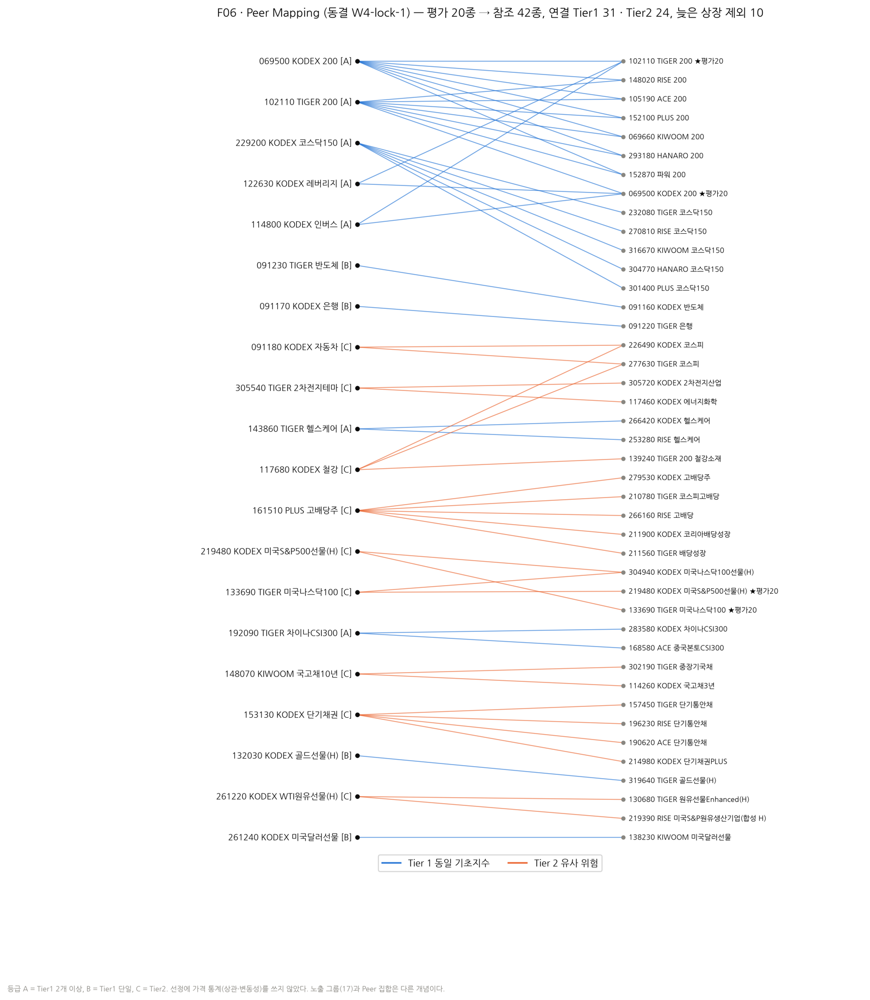

{"n_peers": 42, "tier1_edges": 31, "tier2_edges": 24, "late_excluded": 10}


In [5]:
CAP["F06_peer_network"] = FG.f06_network()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F06_peer_network.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F06_peer_network"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F06).**
- 평가 20종은 Peer 42종에 연결된다. 연결은 Tier 1 31개, Tier 2 24개이고, 늦은 상장으로 10개를 제외했다.
- `PEER_UNAVAILABLE` 은 0개다. 따라서 17/17 판정이 Peer 부족 때문에 막히는 날은 없다.
- 약한 매핑은 C 등급 9종이다.
  - 091180·117680 은 업종을 시장 전체와 비교한다.
  - 148070 의 Peer 는 듀레이션이 짧다.
  - 261220 의 둘째 Peer 는 원유 생산기업 주식이다.
  - 133690·219480 은 서로를 Peer 로 쓴다.
- 이 약점은 결과를 보기 전에 계약에 적었다.

In [6]:
# Peer 품질 사후 진단 (동결 이후 계산 — 선정에 쓰지 않음): 로그비율의 흔들림과 σ 순위상관.
PQ = pd.read_csv(RES / "peer_mapping_quality.csv", dtype={"eval_ticker": str})  # 사후 품질표
display(PQ[PQ["q"] == 20][["eval_ticker", "status", "grade", "peers", "L_sd", "L_abs_median", "sigma_spearman_with_peer_median"]].round(3))  # q=20 기준

,eval_ticker,status,grade,peers,L_sd,L_abs_median,sigma_spearman_with_peer_median
0,069500,TIER1,A,102110|148020|105190|152100|069660|293180|152870,0.015,0.009,0.999
2,102110,TIER1,A,069500|148020|105190|152100|069660|293180|152870,0.017,0.009,0.998
4,122630,TIER1,A,069500|102110,0.019,0.011,0.998
6,114800,TIER1,A,069500|102110,0.028,0.027,0.997
8,229200,TIER1,A,232080|270810|316670|304770|301400,0.028,0.020,0.994
10,091230,TIER1,B,091160,0.053,0.034,0.981
12,091170,TIER1,B,091220,0.058,0.033,0.982
14,091180,TIER2,C,226490|277630,0.245,0.352,0.689
16,305540,TIER2,C,305720|117460,0.090,0.139,0.948
18,143860,TIER1,A,266420|253280,0.065,0.038,0.973


**해석 (Peer 품질).**
- 동일 지수 Peer(A·B 등급)는 σ 순위상관이 0.94(192090)–0.999 다. 그래서 로그비율 L 의 표준편차가 0.015–0.10 으로 작다.
- Tier 2 는 σ 순위상관이 낮다. 117680 이 0.525, 153130 이 0.675, 091180 이 0.689 다. L 의 표준편차도 0.09–0.445 로 크다 (117680 0.332, 153130 0.445).
- 따라서 같은 B 라도 의미가 다르다.
  - Tier 1 의 B 는 추적 차이·호가·유동성 차이의 이례적 확대다.
  - Tier 2 의 B 는 업종·듀레이션 고유 변동성이 평소 관계에서 벗어난 상태다.

## 4. 연환산 변동성 정의

- 수익률: `r = 100·log(C_t / C_{t−1})` (일간 %). 결측 가격은 채우지 않는다.
- 변동성: `σ(q) = √252 · std(r_{t−q+1..t}, ddof=1)` (연환산 %), q ∈ {20, 60}.
- 배율 정규화: `σ_adj = σ / |m|`. 122630 은 ÷2, 114800 은 ÷1 이다.
- 과거 분위: **엄밀 과거** 확장형 mid-rank 로 계산한다 (최소 252개, W2 와 같은 함수). 당일 값은 기준에 넣지 않는다.

W2 는 `mean(r²)`(평균 0 가정·ddof 0)를 썼다. 두 정의가 같은 원자료에서 얼마나 다른지 §14 에서 분리해 잰다.

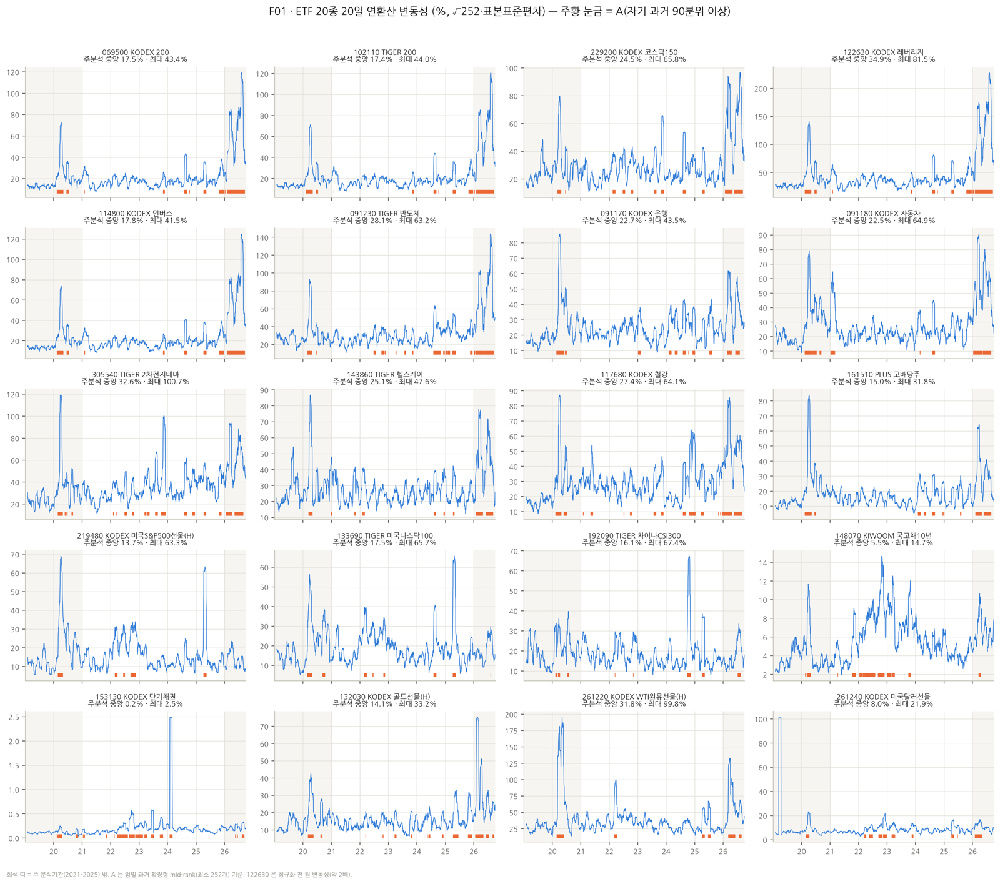

{"069500": {"median": 17.47, "max": 43.42, "A_days": 95}, "102110": {"median": 17.39, "max": 44.03, "A_days": 95}, "229200": {"median": 24.47, "max": 65.85, "A_days": 121}, "122630": {"median": 34.93, "max": 81.55, "A_days": 96}, "114800": {"median": 17.81, "max": 41.55, "A_days": 97}, "091230": {"median": 28.06, "max": 63.16, "A_days": 192}, "091170": {"median": 22.68, "max": 43.46, "A_days": 110}, "091180": {"median": 22.5, "max": 64.86, "A_days": 53}, "305540": {"median": 32.64, "max": 100.7, "A_days": 197}, "143860": {"median": 25.11, "max": 47.59, "A_days": 48}, "117680": {"median": 27.35, "max": 64.14, "A_days": 174}, "161510": {"median": 14.95, "max": 31.79, "A_days": 75}, "219480": {"median": 13.68, "max": 63.31, "A_days": 76}, "133690": {"median": 17.51, "max": 65.66, "A_days": 80}, "192090": {"median": 16.07, "max": 67.36, "A_days": 49}, "148070": {"median": 5.52, "max": 14.68,


In [7]:
CAP["F01_sigma20_grid"] = FG.f_sigma_grid(20, "F01_sigma20_grid")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F01_sigma20_grid.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F01_sigma20_grid"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F01).**
- 20일 σ 의 주분석(2021–2025) 중앙값은 ETF 마다 크게 다르다. 153130 단기채권이 0.2% 로 가장 낮고, 122630 레버리지가 34.9% 로 가장 높다.
- 고정 % 임계값이 자산마다 다른 뜻을 갖는 이유다. 그래서 A 는 절대 수준이 아니라 **자기 과거 분위**로 정의한다.
- 원자료 이상치 두 건이 그림에 보인다. 계약에 따라 고치지 않고 기록만 한다.
  - 261240 의 2019-03-14 종가가 11,820원이다. 전후 거래일은 9,690원·9,730원이라 하루 +19.9% 다음 날 −19.5% 다.
  - 153130 은 2024-01-30·31 에 ±0.5% 로 움직였다. 분배 조정이 의심된다.
  - 261240 이상치는 2019(기준 전용)에 있지만 이후 확장형 기준분포에 남는다.

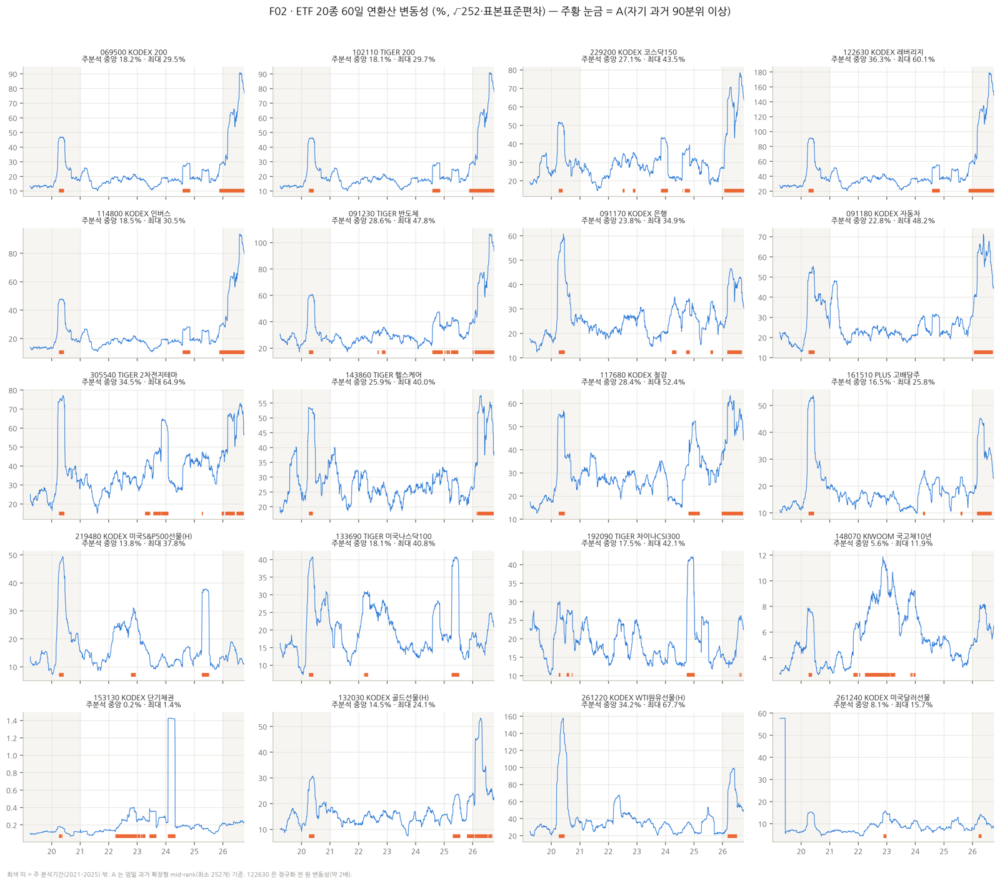

{"069500": {"median": 18.17, "max": 29.5, "A_days": 90}, "102110": {"median": 18.13, "max": 29.72, "A_days": 90}, "229200": {"median": 27.13, "max": 43.48, "A_days": 126}, "122630": {"median": 36.32, "max": 60.13, "A_days": 91}, "114800": {"median": 18.53, "max": 30.49, "A_days": 88}, "091230": {"median": 28.61, "max": 47.8, "A_days": 186}, "091170": {"median": 23.76, "max": 34.95, "A_days": 74}, "091180": {"median": 22.76, "max": 48.16, "A_days": 0}, "305540": {"median": 34.51, "max": 64.9, "A_days": 169}, "143860": {"median": 25.93, "max": 40.04, "A_days": 0}, "117680": {"median": 28.41, "max": 52.41, "A_days": 97}, "161510": {"median": 16.54, "max": 25.79, "A_days": 28}, "219480": {"median": 13.81, "max": 37.81, "A_days": 97}, "133690": {"median": 18.12, "max": 40.8, "A_days": 79}, "192090": {"median": 17.46, "max": 42.14, "A_days": 64}, "148070": {"median": 5.56, "max": 11.88, "A_day


In [8]:
CAP["F02_sigma60_grid"] = FG.f_sigma_grid(60, "F02_sigma60_grid")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F02_sigma60_grid.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F02_sigma60_grid"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

## 5. A — 자기 과거 대비 고변동성

`A = 1[U_A ≥ 0.90]`, `U_A` 는 같은 ETF 의 과거 같은 q 변동성 분포에서 오늘 σ 의 mid-rank 위치다. 기준 부족은 0 이 아니라 NA 다. 0.90 은 라벨 정의를 위한 사전 선택값이며 유의수준이 아니다.

In [9]:
# ETF 별 A·B 발생률 (주분석 2021–2025).
ST = pd.read_csv(RES / "etf_state_summary.csv", dtype={"ticker": str})  # ETF 상태 요약
cols = ["ticker", "name", "q", "A_rate_primary", "B_UP_rate_primary", "B_DOWN_rate_primary", "AB_rate_primary", "A_max_run", "B_max_run"]  # 표시 열
display(ST[cols].round(3))  # 상태 발생률 표

,ticker,name,q,A_rate_primary,B_UP_rate_primary,B_DOWN_rate_primary,AB_rate_primary,A_max_run,B_max_run
0,069500,KODEX 200,20,0.078,0.025,0.024,0.002,33,19
1,069500,KODEX 200,60,0.073,0.039,0.096,0.019,60,55
2,102110,TIGER 200,20,0.078,0.031,0.051,0.000,33,20
3,102110,TIGER 200,60,0.073,0.076,0.020,0.000,60,59
4,229200,KODEX 코스닥150,20,0.099,0.046,0.019,0.004,24,14
5,229200,KODEX 코스닥150,60,0.103,0.029,0.000,0.000,58,12
6,122630,KODEX 레버리지,20,0.078,0.016,0.054,0.023,33,21
7,122630,KODEX 레버리지,60,0.074,0.004,0.097,0.049,60,61
8,114800,KODEX 인버스,20,0.079,0.054,0.067,0.024,34,23
9,114800,KODEX 인버스,60,0.072,0.060,0.131,0.047,39,60


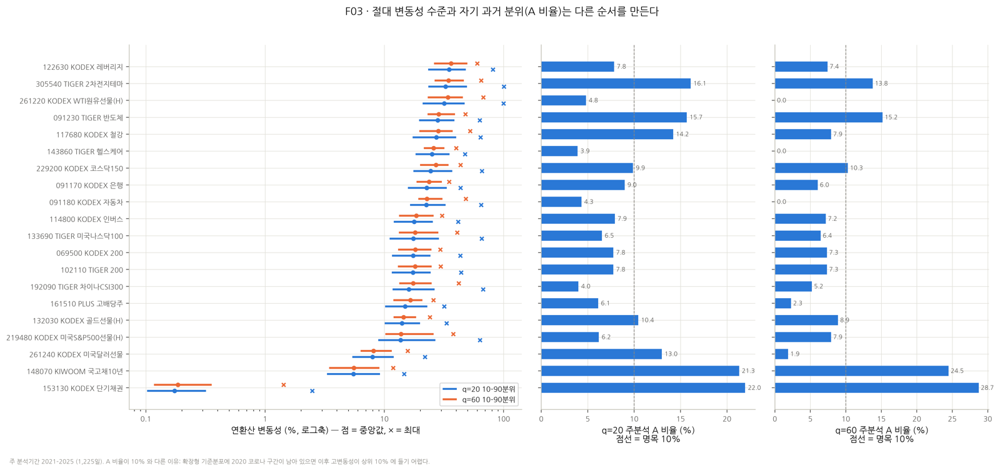

{"zero_A_q60": ["091180", "143860", "261220"], "max_A_q20": ["153130", 0.2195918367]}


In [10]:
CAP["F03_level_vs_rank"] = FG.f03_level_vs_rank()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F03_level_vs_rank.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F03_level_vs_rank"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

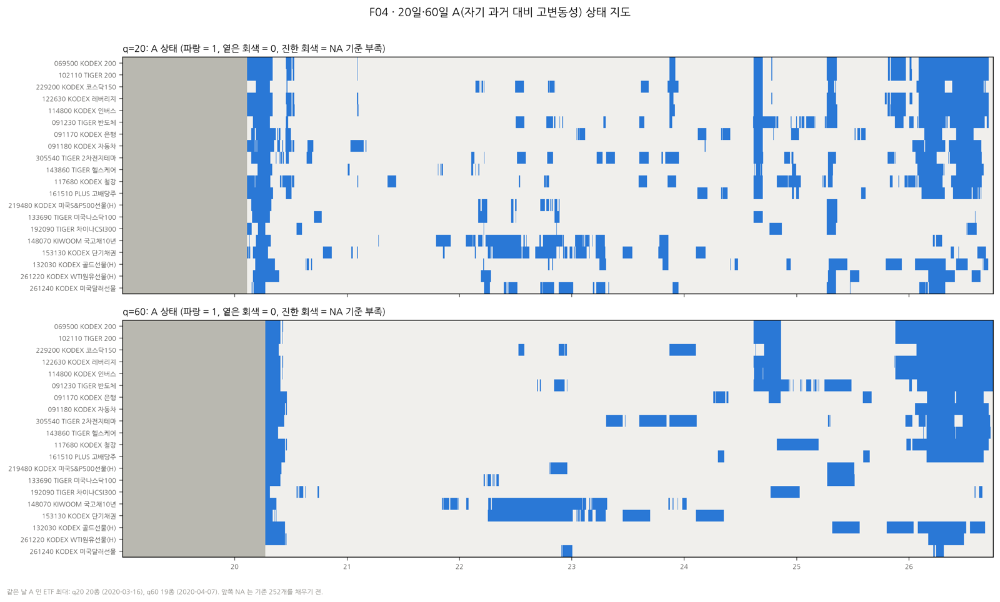

{"q20_max_etf_A_same_day": 20, "q20_max_date": "2020-03-16", "q60_max_etf_A_same_day": 19, "q60_max_date": "2020-04-07"}


In [11]:
CAP["F04_A_heatmap"] = FG.f04_A_heatmap()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F04_A_heatmap.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F04_A_heatmap"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F03·F04).**
- A 비율은 명목 10% 가 아니다. q=20 에서 3.9%(143860)부터 22.0%(153130)까지 퍼져 있다.
- q=60 에서는 091180·143860·261220 의 주분석 A 가 **0일**이다. 확장형 기준분포가 2020 코로나 구간의 극단값을 계속 품고 있기 때문이다. 504일 고정 기준 민감도(§15)에서 q60 최대 A 참여가 6 → 9 그룹으로 오르는 것과 같은 현상이다.
- 반대로 148070·153130 은 2022 금리 충격이 기준분포에 없던 수준이어서 A 비율이 높다 (q60 24.5%·28.7%).
- 같은 날 A 인 ETF 수의 최대는 q=20 에서 **20종 전부**다 (2020-03-16, 파일럿). 주 분석기간에서는 그런 날이 없다.

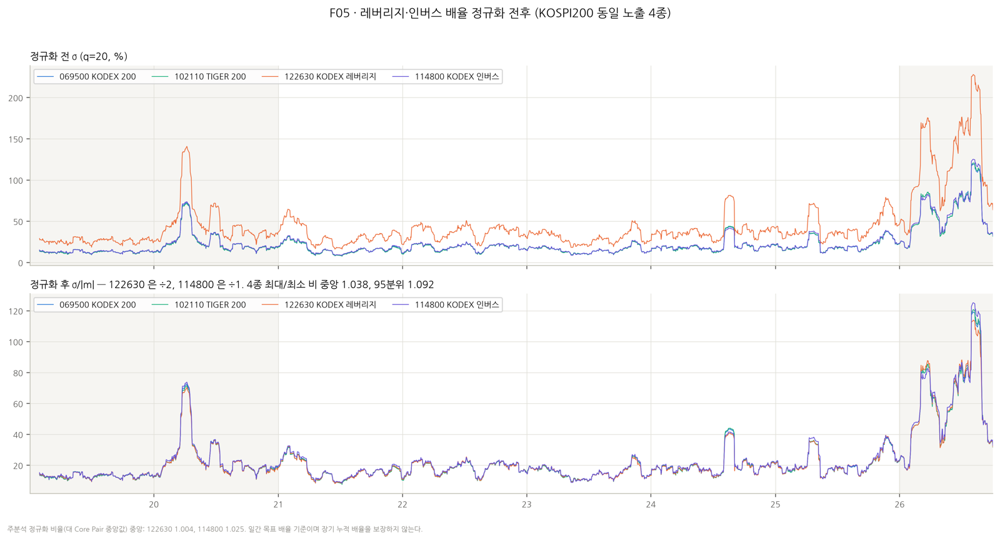

{"ratio_122630": 1.0044, "ratio_114800": 1.0254}


In [12]:
CAP["F05_leverage_normalization"] = FG.f05_leverage_norm()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F05_leverage_normalization.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F05_leverage_normalization"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

## 6. B — Peer 대비 양방향 상대 괴리

`L = log(σ_adj / median Peer σ_adj)`, `U_B` = L 의 엄밀 과거 mid-rank, `B_UP = 1[U_B ≥ 0.95]`, `B_DOWN = 1[U_B ≤ 0.05]`, `B = B_UP ∨ B_DOWN`.

**B_DOWN 은 저변동성이라는 뜻이 아니다.** Peer 가 더 크게 움직여 비율이 떨어졌을 수 있다. 영분산은 epsilon 없이 `ZERO_VOL_*` 로 기록한다.

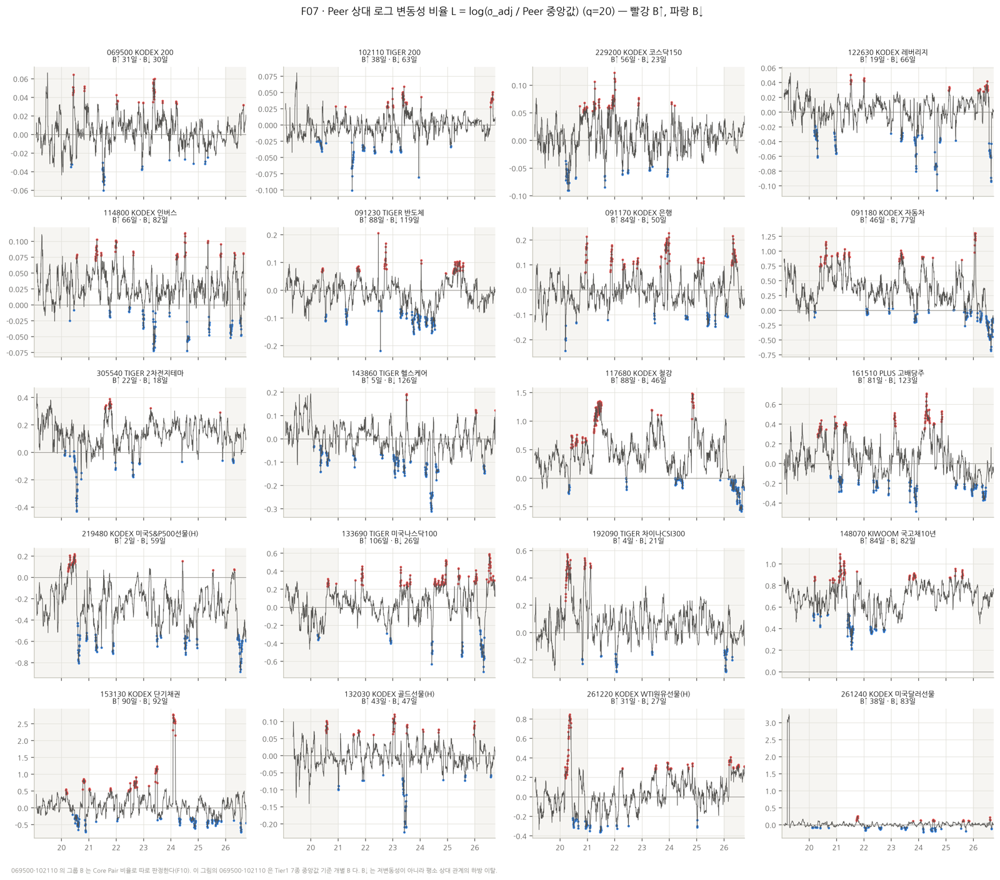

{"069500": {"B_UP": 31, "B_DOWN": 30}, "102110": {"B_UP": 38, "B_DOWN": 63}, "229200": {"B_UP": 56, "B_DOWN": 23}, "122630": {"B_UP": 19, "B_DOWN": 66}, "114800": {"B_UP": 66, "B_DOWN": 82}, "091230": {"B_UP": 88, "B_DOWN": 119}, "091170": {"B_UP": 84, "B_DOWN": 50}, "091180": {"B_UP": 46, "B_DOWN": 77}, "305540": {"B_UP": 22, "B_DOWN": 18}, "143860": {"B_UP": 5, "B_DOWN": 126}, "117680": {"B_UP": 88, "B_DOWN": 46}, "161510": {"B_UP": 81, "B_DOWN": 123}, "219480": {"B_UP": 2, "B_DOWN": 59}, "133690": {"B_UP": 106, "B_DOWN": 26}, "192090": {"B_UP": 4, "B_DOWN": 21}, "148070": {"B_UP": 84, "B_DOWN": 82}, "153130": {"B_UP": 90, "B_DOWN": 92}, "132030": {"B_UP": 43, "B_DOWN": 47}, "261220": {"B_UP": 31, "B_DOWN": 27}, "261240": {"B_UP": 38, "B_DOWN": 83}}


In [13]:
CAP["F07_peer_ratio_grid"] = FG.f07_ratio_grid()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F07_peer_ratio_grid.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F07_peer_ratio_grid"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

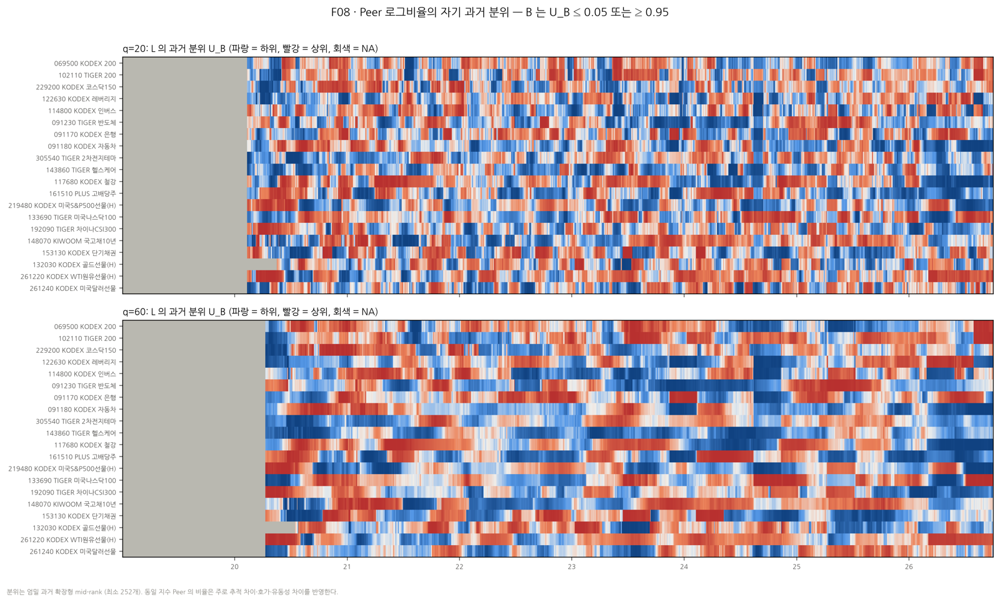

{}


In [14]:
CAP["F08_peer_ratio_rank_heat"] = FG.f08_UB_heat()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F08_peer_ratio_rank_heat.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F08_peer_ratio_rank_heat"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

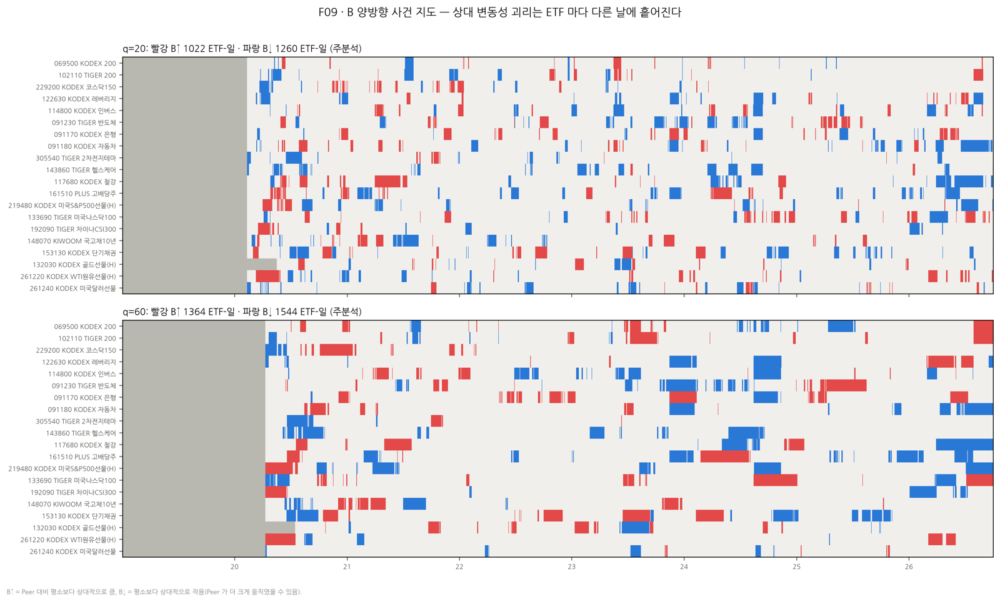

{"q20": {"up": 1022, "down": 1260}, "q60": {"up": 1364, "down": 1544}}


In [15]:
CAP["F09_B_direction_map"] = FG.f09_B_map()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F09_B_direction_map.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F09_B_direction_map"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F07–F09).**
- 주분석 B 는 q=20 에서 B↑ 1,022 · B↓ 1,260 ETF-일, q=60 에서 B↑ 1,364 · B↓ 1,544 ETF-일이다. **하방 이탈이 상방보다 많다.**
- B 는 ETF 마다 다른 날에 흩어진다 (F09). 같은 날 B 인 그룹은 주분석 최대 7/17 이다.
- 상대 괴리는 그 자산 고유의 이탈이다. 여러 자산이 같은 날 함께 '평소 관계에서 벗어나는' 일은 드물다. 이것이 §11 에서 보게 될 17/17 병목의 직접 원인이다.

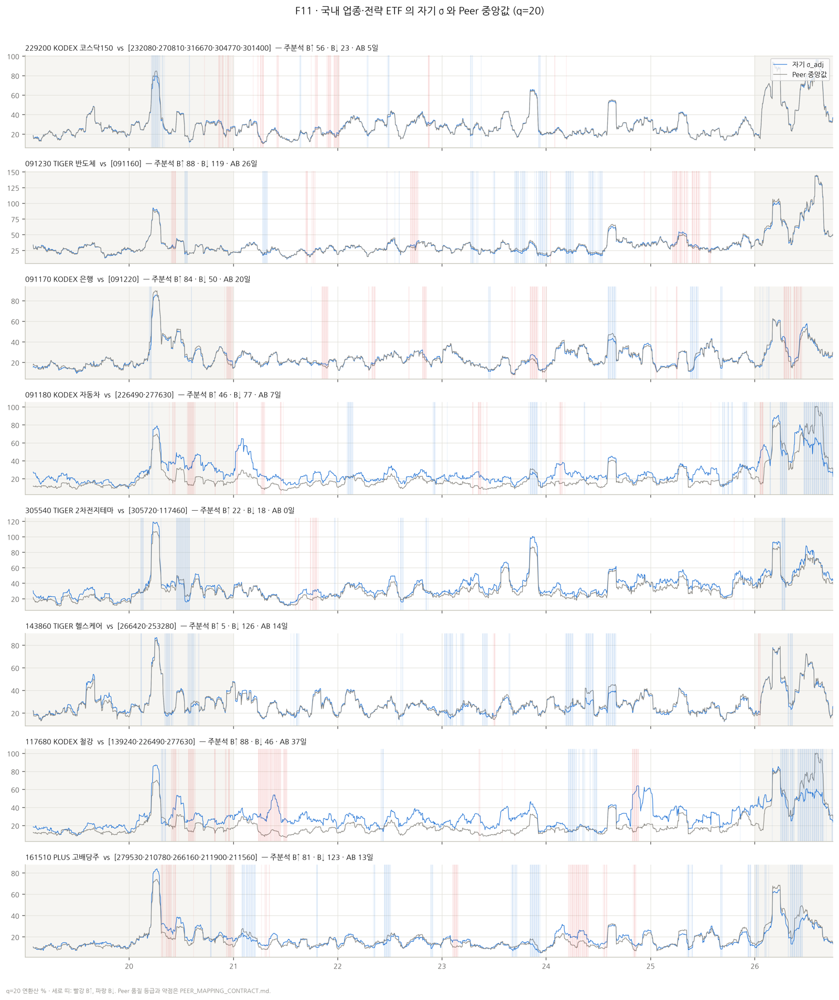

{"229200": {"B_UP": 56, "B_DOWN": 23, "AB": 5}, "091230": {"B_UP": 88, "B_DOWN": 119, "AB": 26}, "091170": {"B_UP": 84, "B_DOWN": 50, "AB": 20}, "091180": {"B_UP": 46, "B_DOWN": 77, "AB": 7}, "305540": {"B_UP": 22, "B_DOWN": 18, "AB": 0}, "143860": {"B_UP": 5, "B_DOWN": 126, "AB": 14}, "117680": {"B_UP": 88, "B_DOWN": 46, "AB": 37}, "161510": {"B_UP": 81, "B_DOWN": 123, "AB": 13}}


In [16]:
CAP["F11_domestic_peer"] = FG._own_vs_peer(["229200", "091230", "091170", "091180", "305540", "143860", "117680", "161510"], "F11_domestic_peer", "F11 · 국내 업종·전략 ETF 의 자기 σ 와 Peer 중앙값 (q=20)")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F11_domestic_peer.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F11_domestic_peer"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

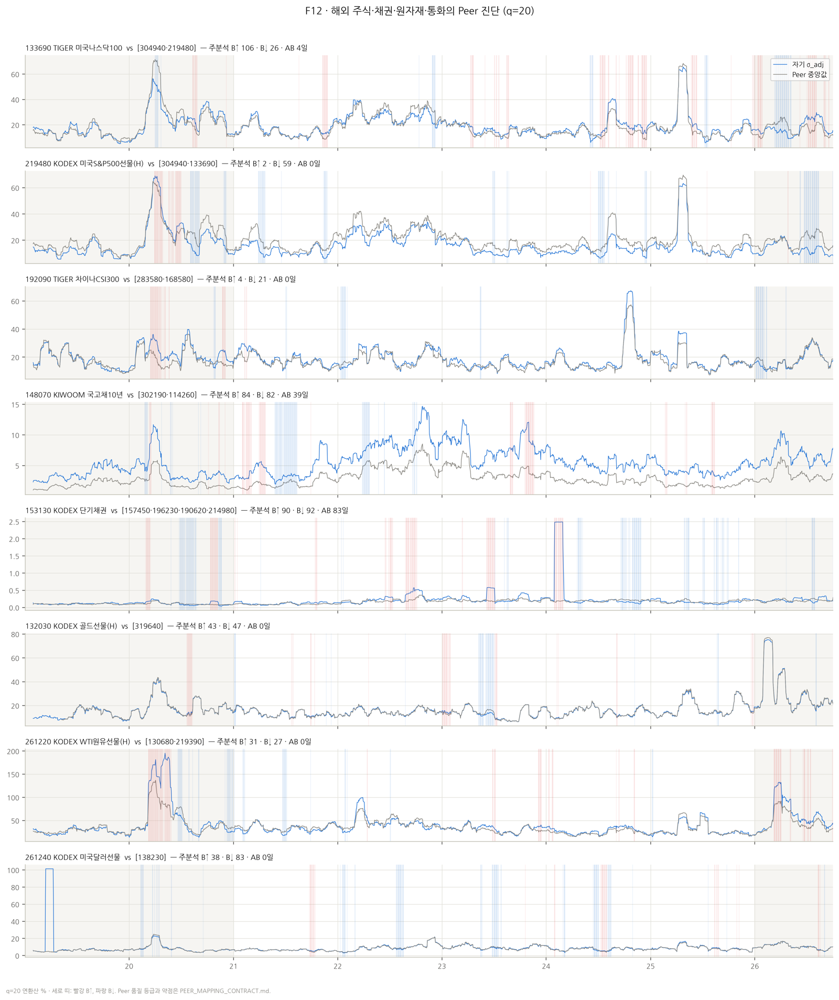

{"133690": {"B_UP": 106, "B_DOWN": 26, "AB": 4}, "219480": {"B_UP": 2, "B_DOWN": 59, "AB": 0}, "192090": {"B_UP": 4, "B_DOWN": 21, "AB": 0}, "148070": {"B_UP": 84, "B_DOWN": 82, "AB": 39}, "153130": {"B_UP": 90, "B_DOWN": 92, "AB": 83}, "132030": {"B_UP": 43, "B_DOWN": 47, "AB": 0}, "261220": {"B_UP": 31, "B_DOWN": 27, "AB": 0}, "261240": {"B_UP": 38, "B_DOWN": 83, "AB": 0}}


In [17]:
CAP["F12_overseas_bond_cmd_fx_peer"] = FG._own_vs_peer(["133690", "219480", "192090", "148070", "153130", "132030", "261220", "261240"], "F12_overseas_bond_cmd_fx_peer", "F12 · 해외 주식·채권·원자재·통화의 Peer 진단 (q=20)")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F12_overseas_bond_cmd_fx_peer.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F12_overseas_bond_cmd_fx_peer"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F11·F12).**
- 업종 대 시장 비교(091180·117680)에서는 업종 σ 가 시장 σ 보다 대부분 위에 있다 (주분석 L > 0 인 날 94.5%·96.1%). 그래서 B 는 그 간격이 평소보다 벌어지거나 좁혀진 날이다.
- 148070 은 Peer(중장기·3년 국채)보다 σ 가 높다 (|L| 중앙 0.714). 2022 금리 충격 때는 A 와 **B↓** 가 28일 겹쳤다. 짧은 듀레이션 Peer 의 변동성이 평소 비율보다 더 크게 올랐다는 뜻이다. 같은 해 153130 은 A∧B↑ 가 38일이다.
- 132030 의 Peer 319640 은 2019-04-09 부터 관측된다. 그래서 2020 상반기 B 가 NA 다 (F33).

## 7. KOSPI200 4종 심층 사례

- 그룹 A 는 Core Pair(069500·102110) **둘 다** A 일 때다.
- 그룹 B 는 `log(σ069500 / σ102110)` 의 과거 양측 5% 이탈이다.
- 레버리지·인버스는 배율 정규화 후 Core Pair 와 비교한 **보조 진단**이다. 그룹 판정에서 거부권이 없다.

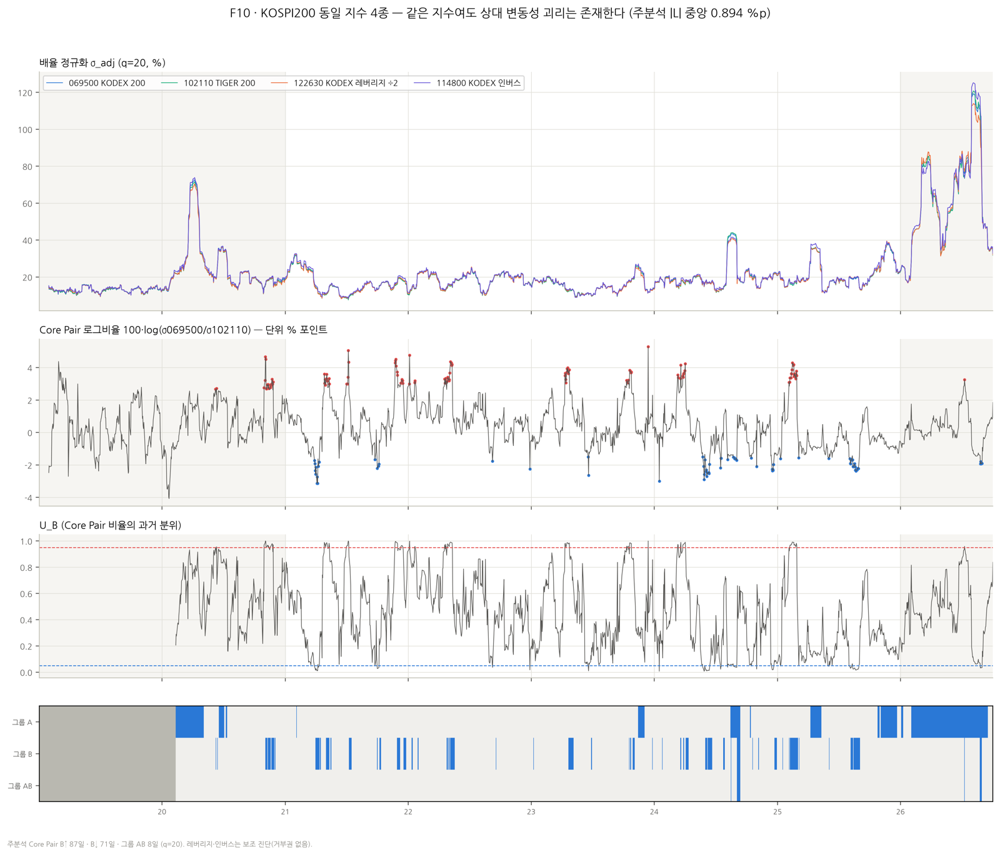

{"core_L_abs_median_pctpt": 0.894, "core_B_UP": 87, "core_B_DOWN": 71, "group_AB_days": 8}


In [18]:
CAP["F10_kospi200_four"] = FG.f10_kospi()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F10_kospi200_four.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F10_kospi200_four"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

In [19]:
# 레버리지·인버스 보조 진단표 (§7.1): 배율 정규화 비율·A/B 일치도·4종 상대 변동성 범위.
AUX = pd.read_csv(RES / "kospi200_aux_diagnostics.csv", dtype={"ticker": str})  # 보조 진단
display(AUX.round(4))  # 표 표시

,q,ticker,multiplier,adj_ratio_to_core_median,adj_ratio_p05,adj_ratio_p95,A_days,core_A_days,A_agreement,A_jaccard,B_days,core_B_days,B_UP_days,B_DOWN_days,B_agreement,B_jaccard,four_range_median,four_range_p95,four_range_max
0,20,122630,2,1.0044,0.9676,1.0216,96,95,0.9894,0.8725,85,158,19,66,0.8359,0.0946,1.0381,1.0921,1.1563
1,20,114800,-1,1.0254,0.9824,1.0778,97,95,0.9935,0.9200,148,158,66,82,0.7992,0.1087,1.0381,1.0921,1.1563
2,60,122630,2,1.0017,0.9637,1.0146,91,90,0.9992,0.9890,124,196,5,119,0.8367,0.2308,1.0357,1.0624,1.0834
3,60,114800,-1,1.0249,0.9923,1.0502,88,90,0.9984,0.9778,234,196,73,161,0.8057,0.2874,1.0357,1.0624,1.0834


**해석 (F10·§7.1).**
- 동일 지수인 Core Pair 사이에도 상대 변동성 괴리가 있다. 주분석에서 |L| 의 중앙값은 0.894 %p 다.
- 과거 양측 꼬리 이탈은 B↑ 87일, B↓ 71일이다 (q=20). 이 B 는 시장 충격이 아니라 두 ETF 의 추적·호가 차이가 평소보다 커진 상태다.
- 배율 정규화 σ 를 Core Pair 중앙값으로 나눈 비율의 중앙값은 다음과 같다. 일간 목표 배율 기준으로는 1배 ETF 와 거의 같다.
  - 122630: 1.004 (5–95분위 0.968–1.022)
  - 114800: 1.025
- A 는 Core Pair 와 98.9–99.9% 일치한다. B 의 Jaccard 는 0.09–0.29 로 낮다. 레버리지·인버스의 상대 괴리는 Core Pair 의 괴리와 다른 날에 생긴다.

## 8. 20종 ETF 상태 전수 분석 — A·B·AB 는 같은 날인가

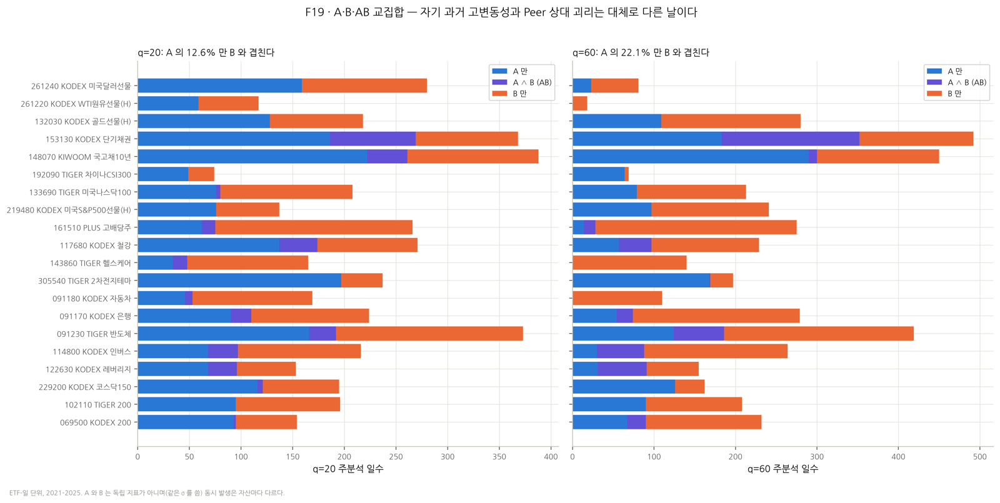

{"q20": {"A_total": 2434, "AB_total": 307, "B_total": 2282, "AB_share_of_A": 0.1261}, "q60": {"A_total": 2063, "AB_total": 457, "B_total": 2908, "AB_share_of_A": 0.2215}}


In [20]:
CAP["F19_A_B_intersection"] = FG.f19_intersection()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F19_A_B_intersection.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F19_A_B_intersection"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

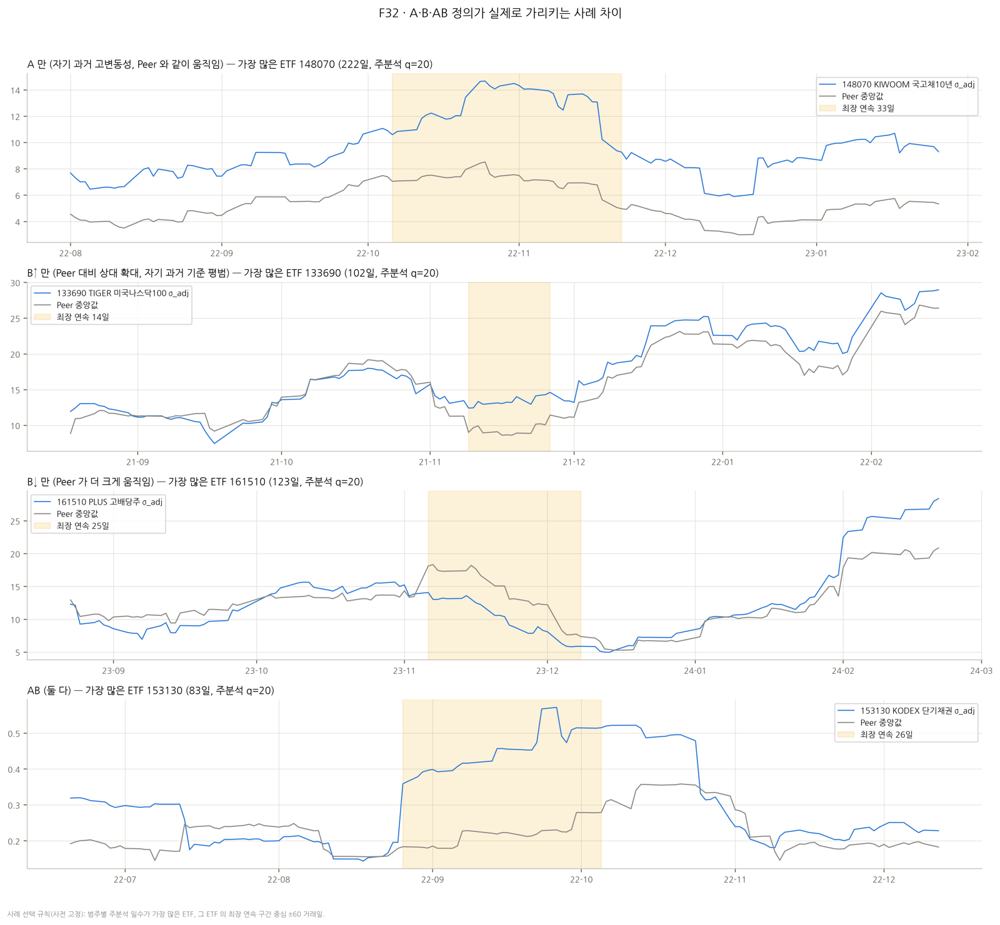

{"A 만 (자기 과거 고변동성, Peer 와 같이 움직임)": {"ticker": "148070", "days": 222, "longest_run": ["2022-10-06", "2022-11-22"]}, "B↑ 만 (Peer 대비 상대 확대, 자기 과거 기준 평범)": {"ticker": "133690", "days": 102, "longest_run": ["2021-11-09", "2021-11-26"]}, "B↓ 만 (Peer 가 더 크게 움직임)": {"ticker": "161510", "days": 123, "longest_run": ["2023-11-06", "2023-12-08"]}, "AB (둘 다)": {"ticker": "153130", "days": 83, "longest_run": ["2022-08-26", "2022-10-05"]}}


In [21]:
CAP["F32_definition_cases"] = FG.f32_cases()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F32_definition_cases.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F32_definition_cases"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F19·F32).**
- A 와 B 는 대체로 다른 날을 가리킨다. A 인 ETF-일 가운데 B 와 겹치는 비율은 q=20 에서 12.6%, q=60 에서 22.1% 다.
- F32 는 범주별로 일수가 가장 많은 ETF 의 최장 연속 구간을 보여 준다 (선택 규칙은 사전 고정).
  - **A 만** — 148070 (2022 하반기): 자기 과거 대비로는 높지만 Peer 도 같이 올랐다.
  - **B↑ 만** — 133690 (2021-11): 자기 과거 기준으로는 평범하지만 Peer(환헤지 미국 선물) 대비 상대적으로 컸다.
  - **B↓ 만** — 161510 (2023-11): Peer 가 더 크게 움직였다.
  - **AB** — 153130 (2022-09): 단기채 σ 가 자기 과거 대비 높으면서 Peer 대비로도 평소보다 컸다.

## 9. 17개 노출 그룹 집계

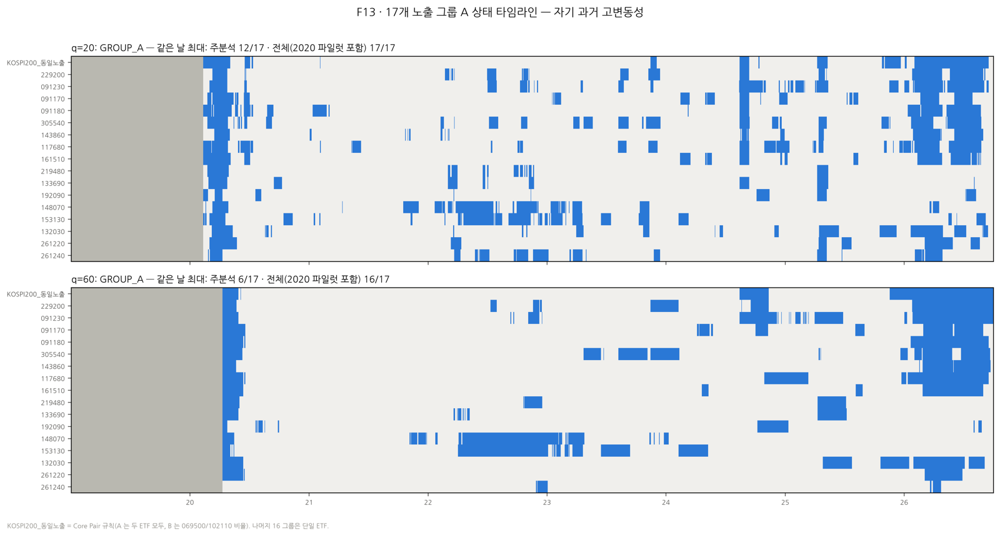

{"q20_max_primary": 12, "q20_max_all": 17, "q60_max_primary": 6, "q60_max_all": 16}


In [22]:
CAP["F13_group_A_timeline"] = FG.f_group_timeline("A", "13")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F13_group_A_timeline.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F13_group_A_timeline"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

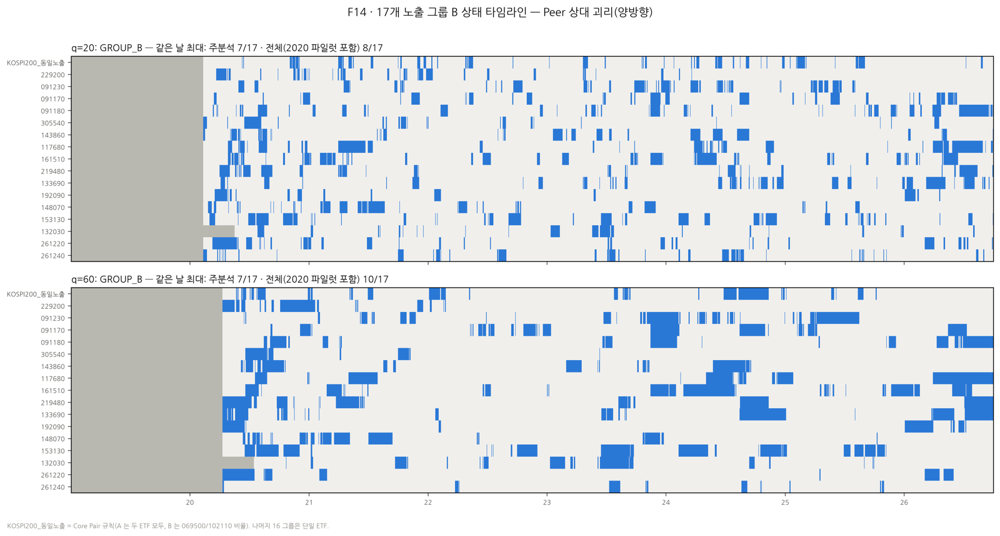

{"q20_max_primary": 7, "q20_max_all": 8, "q60_max_primary": 7, "q60_max_all": 10}


In [23]:
CAP["F14_group_B_timeline"] = FG.f_group_timeline("B", "14")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F14_group_B_timeline.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F14_group_B_timeline"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

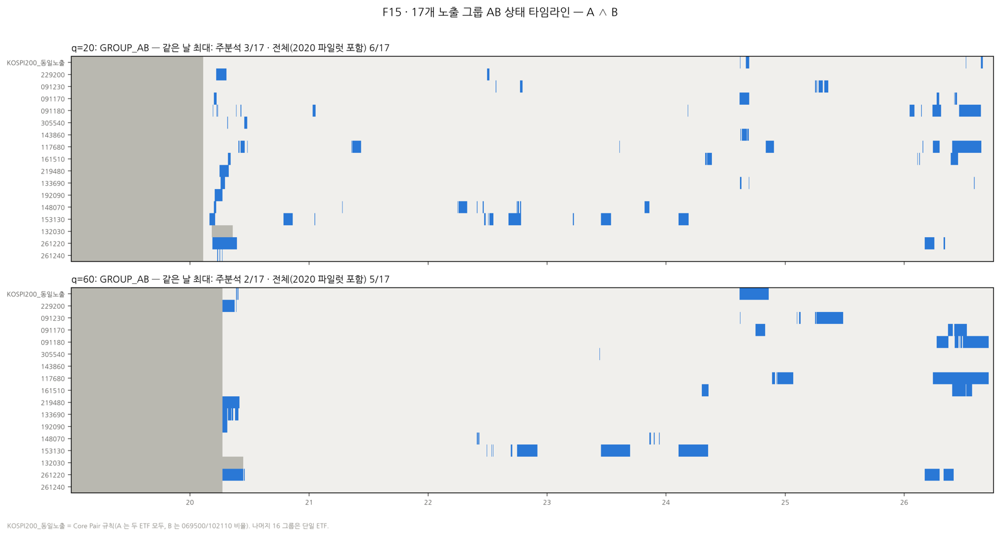

{"q20_max_primary": 3, "q20_max_all": 6, "q60_max_primary": 2, "q60_max_all": 5}


In [24]:
CAP["F15_group_AB_timeline"] = FG.f_group_timeline("AB", "15")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F15_group_AB_timeline.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F15_group_AB_timeline"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

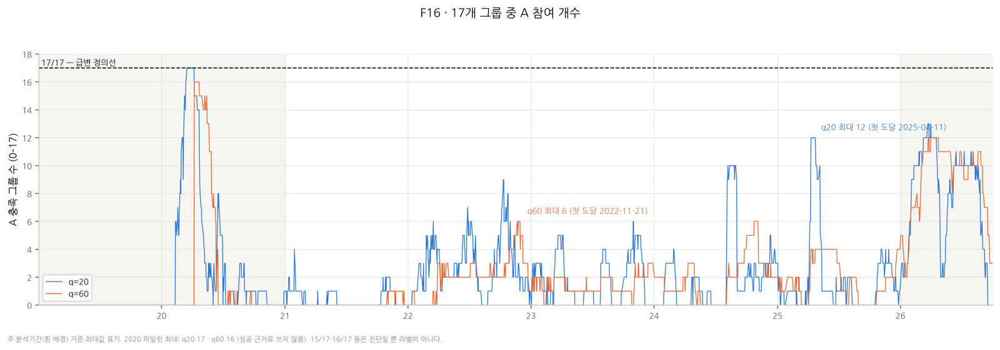

{"q20_max": 12, "q20_max_date": "2025-04-11", "q60_max": 6, "q60_max_date": "2022-11-21", "pilot_max": {"20": 17, "60": 16}}


In [25]:
CAP["F16_count_A"] = FG.f_count("A", "16")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F16_count_A.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F16_count_A"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

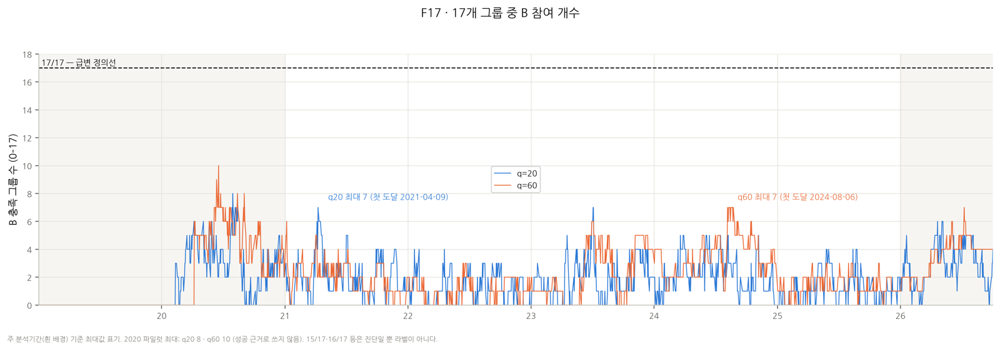

{"q20_max": 7, "q20_max_date": "2021-04-09", "q60_max": 7, "q60_max_date": "2024-08-06", "pilot_max": {"20": 8, "60": 10}}


In [26]:
CAP["F17_count_B"] = FG.f_count("B", "17")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F17_count_B.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F17_count_B"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

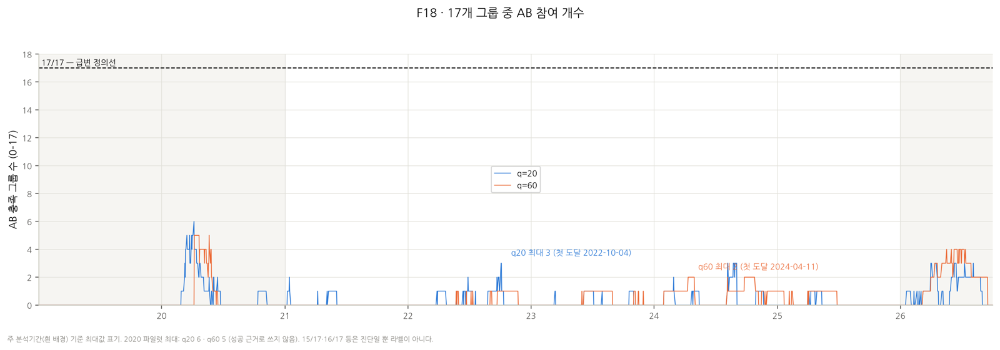

{"q20_max": 3, "q20_max_date": "2022-10-04", "q60_max": 2, "q60_max_date": "2024-04-11", "pilot_max": {"20": 6, "60": 5}}


In [27]:
CAP["F18_count_AB"] = FG.f_count("AB", "18")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F18_count_AB.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F18_count_AB"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F13–F18).**

주분석 최대 참여 그룹 수와 그 값에 도달한 날 **전부** (`results/max_participation_days.csv`):

| 상태 | q=20 | q=60 |
|---|---|---|
| A | 12/17 · 9일 · 2025-04-11~04-23 | 6/17 · 14일 · 2022-11-21~22, 2022-11-24~29, 2024-10-24~11-04 |
| B | 7/17 · 3일 · 2021-04-09, 2023-07-04~05 | 7/17 · 9일 · 2024-08-06~08-23 (4 구간) |
| AB | 3/17 · 10일 · 2022-10-04~05, 2024-08-06~07, 2024-08-23~26, 2024-08-28~09-02 | 2/17 · 34일 · 2024-04-11~29, 2024-08-06, 2024-09-25~10-25 |

- **2020 파일럿**에서는 q=20 A 가 2020-03-16 ~ 04-06 동안 **17/17 을 16일** 충족했다. 그날 B 는 3–6/17 에 그쳤다.
- 즉 A 만이라면 시장 공통 급변이 한 번 관찰된다. 상대 괴리 B 를 동시에 요구하면 공통성이 사라진다.
- 2020 은 파일럿이라 성공 근거로 쓰지 않는다.

## 10. 20일·60일 글로벌 급변

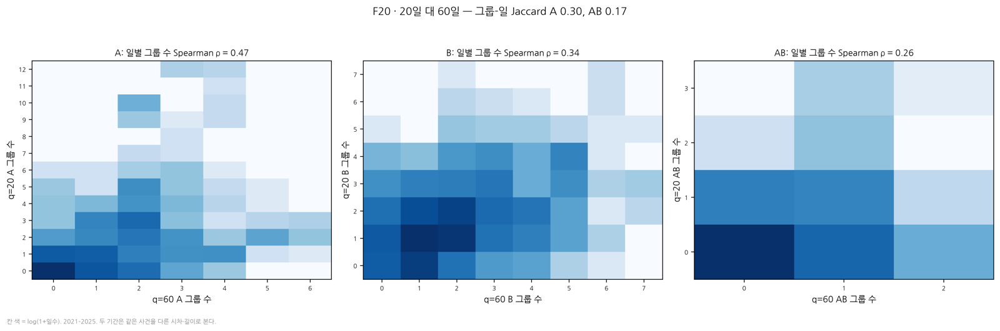

{"A": 0.4742, "B": 0.3363, "AB": 0.2596, "jaccard_group_day_A": 0.3033, "jaccard_group_day_AB": 0.1747}


In [28]:
CAP["F20_horizon_20_vs_60"] = FG.f20_horizons()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F20_horizon_20_vs_60.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F20_horizon_20_vs_60"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

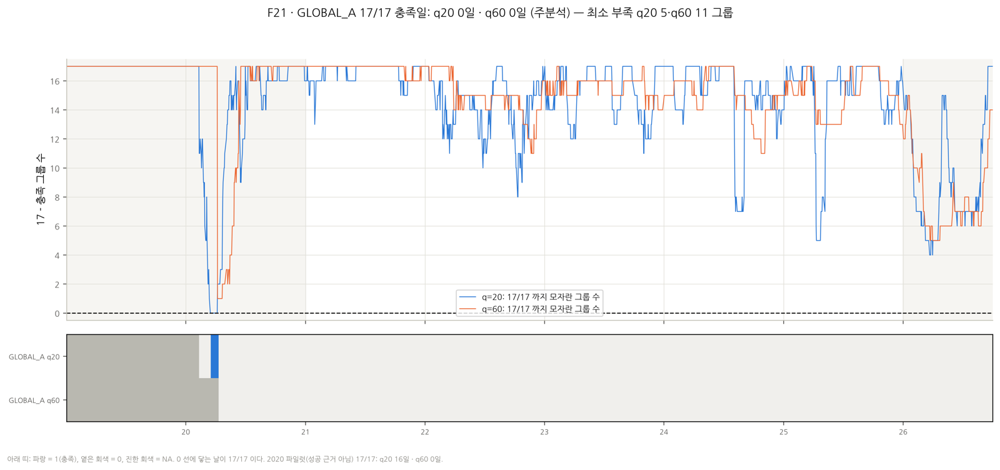

{"q20_days17": 0, "q20_min_gap": 5, "q20_pilot_days17": 16, "q60_days17": 0, "q60_min_gap": 11, "q60_pilot_days17": 0}


In [29]:
CAP["F21_global_A_17of17"] = FG.f_global("A", "21")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F21_global_A_17of17.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F21_global_A_17of17"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

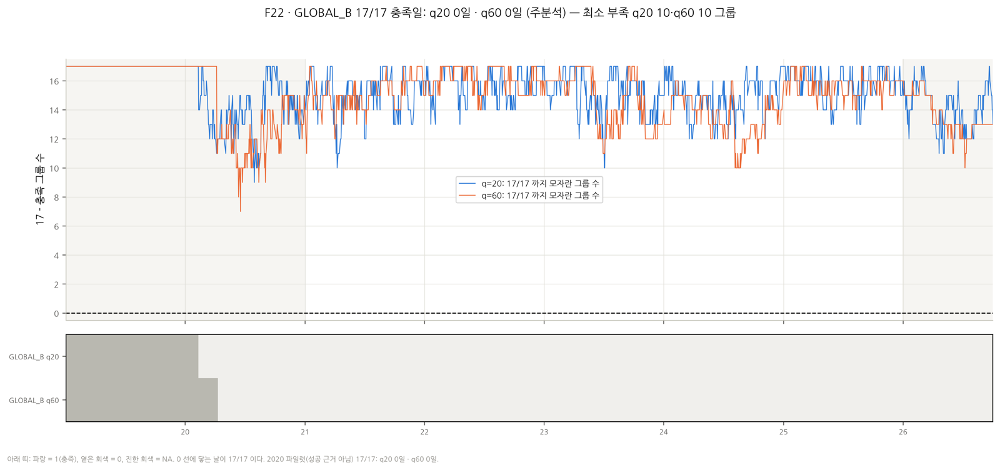

{"q20_days17": 0, "q20_min_gap": 10, "q20_pilot_days17": 0, "q60_days17": 0, "q60_min_gap": 10, "q60_pilot_days17": 0}


In [30]:
CAP["F22_global_B_17of17"] = FG.f_global("B", "22")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F22_global_B_17of17.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F22_global_B_17of17"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

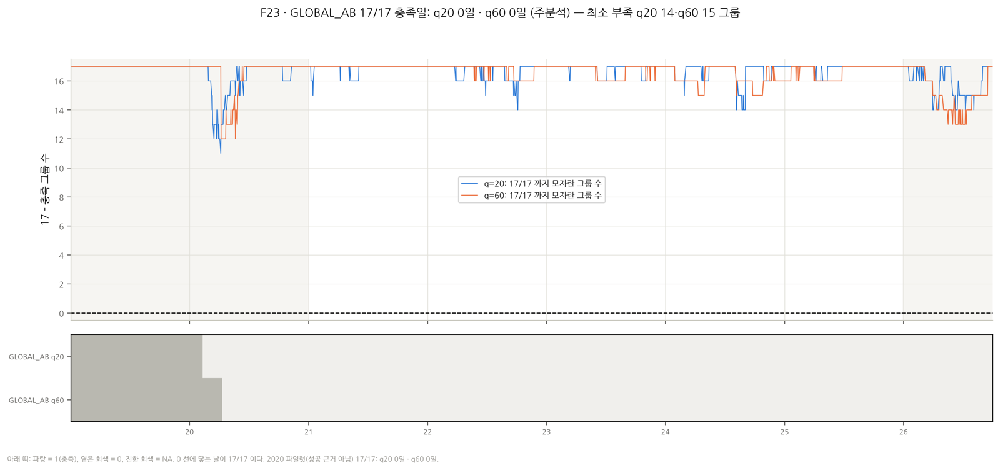

{"q20_days17": 0, "q20_min_gap": 14, "q20_pilot_days17": 0, "q60_days17": 0, "q60_min_gap": 15, "q60_pilot_days17": 0}


In [31]:
CAP["F23_global_AB_17of17"] = FG.f_global("AB", "23")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F23_global_AB_17of17.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F23_global_AB_17of17"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

In [32]:
# 주분석 최대 참여값에 도달한 날 전부와 연속 구간 (첫 도달일 하나만 보고하지 않는다).
MPD = pd.read_csv(RES / "max_participation_days.csv")  # 최대 참여 도달일 표
display(MPD)  # 표 표시

,q,state,max_groups,n_days_at_max,first_day,spans
0,20,A,12,9,2025-04-11,2025-04-11~2025-04-23
1,20,B,7,3,2021-04-09,2021-04-09~2021-04-09;2023-07-04~2023-07-05
2,20,AB,3,10,2022-10-04,2022-10-04~2022-10-05;2024-08-06~2024-08-07;20...
3,60,A,6,14,2022-11-21,2022-11-21~2022-11-22;2022-11-24~2022-11-29;20...
4,60,B,7,9,2024-08-06,2024-08-06~2024-08-06;2024-08-09~2024-08-13;20...
5,60,AB,2,34,2024-04-11,2024-04-11~2024-04-29;2024-08-06~2024-08-06;20...


In [33]:
# 기간 지위별 17/17 충족일·최대 참여·NA (2019 기준 · 2020 파일럿 · 2021–25 주분석 · 2026 부분).
GBP = pd.read_csv(RES / "global_by_period.csv")  # 기간별 요약
display(GBP)  # 표 표시

,period,q,days,first,last,days17_A,na_A,max_n_A,days17_B,na_B,max_n_B,days17_AB,na_AB,max_n_AB,final_true,final_na
0,REFERENCE_ONLY,20,246,2019-01-02,2019-12-30,0,246,0,0,246,0,0,246,0,0,246
1,PILOT,20,248,2020-01-02,2020-12-30,16,26,17,0,26,8,0,26,6,0,66
2,PRIMARY,20,1225,2021-01-04,2025-12-30,0,0,12,0,0,7,0,0,3,0,0
3,PARTIAL_NON_BLIND,20,184,2026-01-02,2026-10-02,0,0,13,0,0,6,0,0,3,0,0
4,REFERENCE_ONLY,60,246,2019-01-02,2019-12-30,0,246,0,0,246,0,0,246,0,0,246
5,PILOT,60,248,2020-01-02,2020-12-30,0,66,16,0,66,10,0,66,5,0,66
6,PRIMARY,60,1225,2021-01-04,2025-12-30,0,0,6,0,0,7,0,0,2,0,0
7,PARTIAL_NON_BLIND,60,184,2026-01-02,2026-10-02,0,0,12,0,0,7,0,0,4,0,0


**해석 (F20–F23).**
- 20일과 60일은 같은 사건을 다른 시차·길이로 본다. 일별 그룹 수의 Spearman ρ 는 A 0.47, B 0.34, AB 0.26 이다. 그룹-일 Jaccard 는 A 0.30, AB 0.17 이다.
- 주분석 1,225일 동안 GLOBAL_A·GLOBAL_B·GLOBAL_AB 의 17/17 은 두 기간 모두 **0일**이다.
- 17/17 까지의 최소 부족 그룹 수는 다음과 같다.
  - A: q20 5 · q60 11
  - B: 10 · 10
  - AB: 14 · 15

## 11. 즉시 진입·종료 구간과 최종 라벨

In [34]:
# 최종 판정과 구간표. 구간이 0개면 빈 표가 정상이다 (존재하지 않는 구간을 만들지 않는다).
V = M["verdict"]  # 계약 §10 판정
print(json.dumps(R["final"], ensure_ascii=False, indent=1))  # 판정·완전 평가 가능일·파일럿·민감도
IV = pd.read_csv(RES / "shock_intervals.csv")  # 급변 구간표
display(IV)  # 0행이면 구간 없음
FL = pd.read_csv(RES / "final_daily_labels.csv", dtype=str)  # 일별 최종 라벨 (available_from 포함)
display(FL.tail(3))  # 마지막 날은 다음 거래일 미상
assert V["verdict"] == "VALID_ZERO_INTERVALS" and len(IV) == 0  # 이번 실행의 판정

{
 "verdict": {
  "verdict": "VALID_ZERO_INTERVALS",
  "primary_days": 1225,
  "primary_evaluable_days": 1225,
  "primary_evaluable_share": 1.0,
  "primary_final_true_days": 0
 },
 "primary_fully_evaluable": {
  "q20": {
   "days": 1225,
   "all17_A_and_B_non_NA_days": 1225
  },
  "q60": {
   "days": 1225,
   "all17_A_and_B_non_NA_days": 1225
  }
 },
 "pilot_2020_days17": {
  "q20": {
   "A": 16,
   "B": 0,
   "AB": 0
  },
  "q60": {
   "A": 0,
   "B": 0,
   "AB": 0
  }
 },
 "n_intervals": 0,
 "sensitivity_verdicts": {
  "MAIN": "VALID_ZERO_INTERVALS",
  "FIXED_504": "VALID_ZERO_INTERVALS",
  "A_095": "VALID_ZERO_INTERVALS",
  "B_2.5": "VALID_ZERO_INTERVALS",
  "K200_FOUR": "VALID_ZERO_INTERVALS"
 },
 "calendar": [
  "2019-01-02",
  "2026-10-02",
  1903
 ],
 "n_peer_tickers": 38
}


,interval_id,start,end,duration_trading_days,left_censored,right_censored,entry_after,exit_reason


,date,GLOBAL_AB_q20,GLOBAL_AB_q60,FINAL_SHOCK,GLOBAL_A_ANY_HORIZON,GLOBAL_B_ANY_HORIZON,GLOBAL_AB_BOTH_HORIZONS,GLOBAL_AB_20_ONLY,GLOBAL_AB_60_ONLY,available_from
1900,2026-09-30,0,0,0,0,0,0,0,0,2026-10-01
1901,2026-10-01,0,0,0,0,0,0,0,0,2026-10-02
1902,2026-10-02,0,0,0,0,0,0,0,0,NEXT_TRADING_DAY_UNKNOWN


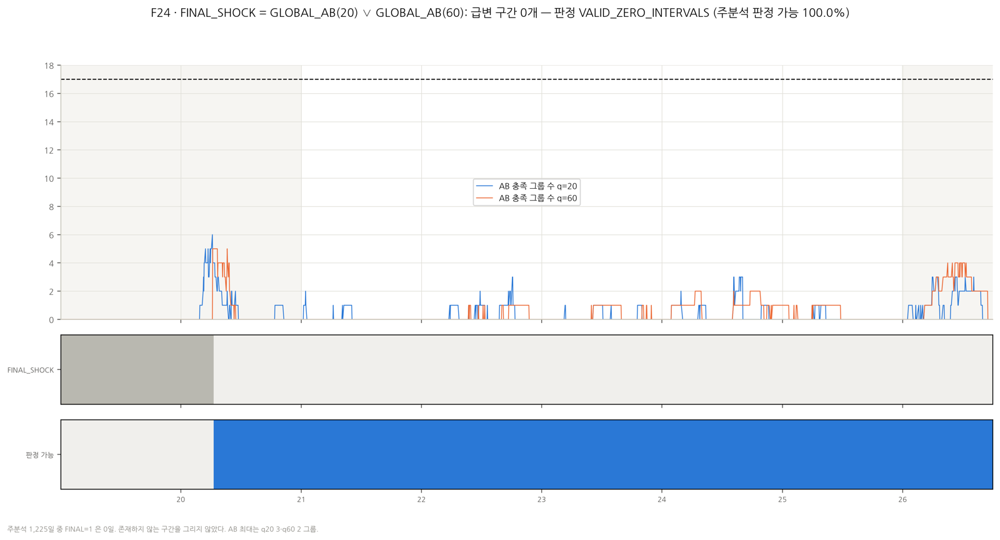

{"n_intervals": 0, "verdict": "VALID_ZERO_INTERVALS", "primary_days": 1225, "primary_evaluable_days": 1225, "primary_evaluable_share": 1.0, "primary_final_true_days": 0}


In [35]:
CAP["F24_final_shock_timeline"] = FG.f24_final()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F24_final_shock_timeline.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F24_final_shock_timeline"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

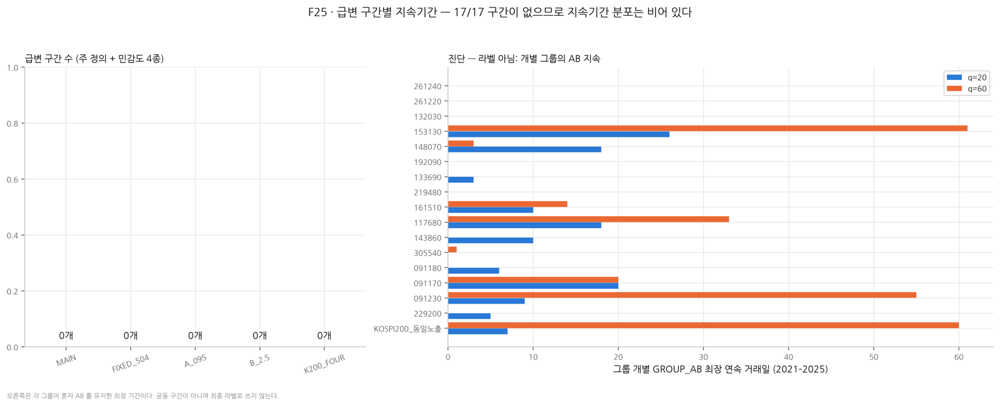

{"intervals_all_variants": [0, 0, 0, 0, 0], "max_group_run": {"20": 26, "60": 61}}


In [36]:
CAP["F25_interval_durations"] = FG.f25_durations()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F25_interval_durations.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F25_interval_durations"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F24·F25).**
- `FINAL_SHOCK = GLOBAL_AB(20) ∨ GLOBAL_AB(60)` 은 주분석 1,225일 동안 판정 가능일이 100%, 1 인 날이 **0일**이다.
- 따라서 급변 구간은 **0개**이고, 판정은 `VALID_ZERO_INTERVALS` 다.
- 같은 구간 규칙을 2019–2026 전체에 적용해도 0개다.
- F25 오른쪽은 각 그룹이 혼자 AB 를 유지한 최장 기간이다 (q20 최대 26일, q60 최대 61일). 공동 구간이 아니므로 라벨로 쓰지 않는다.
- 라벨 사용 시점: t 종가로 만든 라벨은 `available_from`(다음 거래일 장 시작)부터만 쓸 수 있다.

## 12. 17/17 병목 — 왜 0개인가 (계약 §10.1)

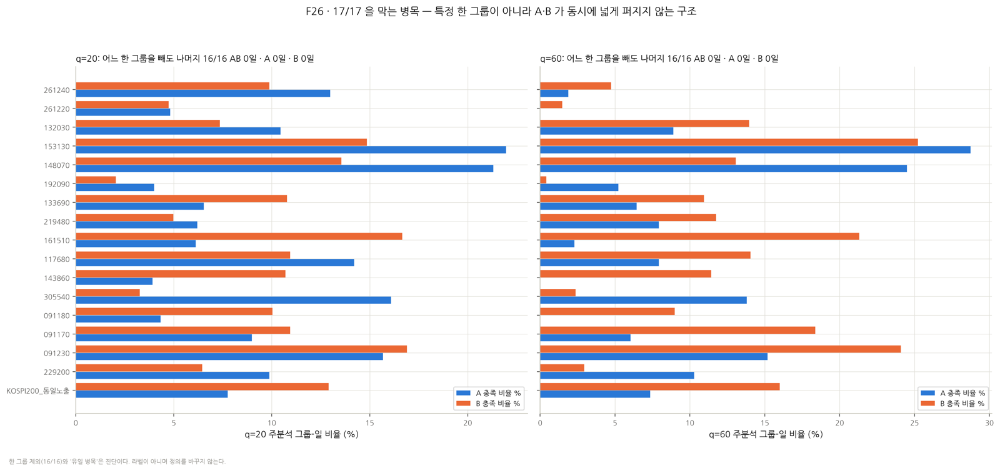

{"q20": {"loo_AB_max": 0, "sole_blocker_AB_max": 0, "loo_A_max": 0, "loo_B_max": 0}, "q60": {"loo_AB_max": 0, "sole_blocker_AB_max": 0, "loo_A_max": 0, "loo_B_max": 0}}


In [37]:
CAP["F26_bottleneck"] = FG.f26_bottleneck()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F26_bottleneck.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F26_bottleneck"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

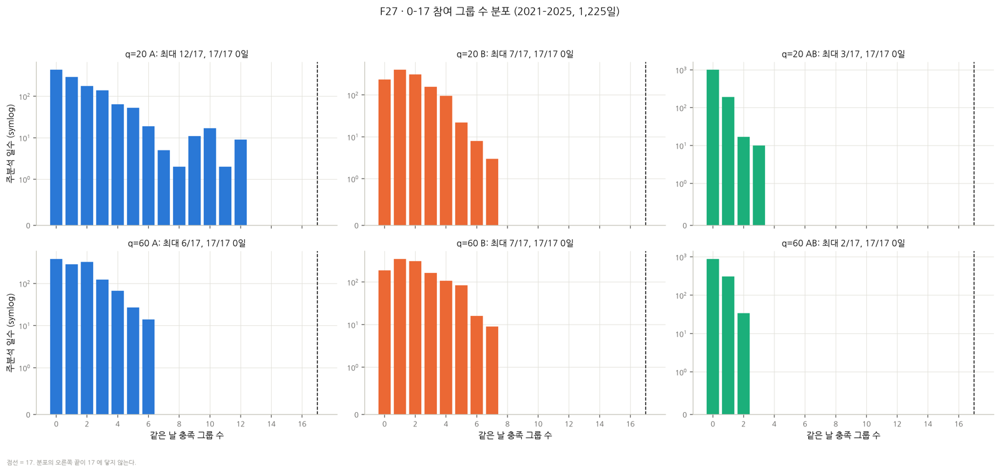

{"q20_A_max": 12, "q20_B_max": 7, "q20_AB_max": 3, "q60_A_max": 6, "q60_B_max": 7, "q60_AB_max": 2}


In [38]:
CAP["F27_participation_distribution"] = FG.f27_distribution()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F27_participation_distribution.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F27_participation_distribution"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

In [39]:
# 병목 수치: 그룹별 A·B 충족률, 한 그룹 제외 16/16 일수(진단), 최대 AB 참여일에 빠진 그룹.
BT = pd.read_csv(RES / "bottleneck_groups.csv")  # 병목 표
display(BT[BT["q"] == 20][["group", "A_false_share", "B_false_share", "loo_A_16of16_days", "loo_B_16of16_days", "loo_AB_16of16_days", "missing_on_max_AB_days", "n_max_AB_days"]].round(3))  # q=20 병목 표 표시

,group,A_false_share,B_false_share,loo_A_16of16_days,loo_B_16of16_days,loo_AB_16of16_days,missing_on_max_AB_days,n_max_AB_days
0,KOSPI200_동일노출,0.922,0.871,0,0,0,3,10
1,229200,0.901,0.936,0,0,0,10,10
2,091230,0.843,0.831,0,0,0,8,10
3,091170,0.910,0.891,0,0,0,2,10
4,091180,0.957,0.900,0,0,0,10,10
5,305540,0.839,0.967,0,0,0,10,10
6,143860,0.961,0.893,0,0,0,4,10
7,117680,0.858,0.891,0,0,0,10,10
8,161510,0.939,0.833,0,0,0,10,10
9,219480,0.938,0.950,0,0,0,10,10


**해석 (§10.1 원인 분해 — 수치만, 정의 변경 없음).**

1. **A 가 17개 모두 함께 나타나지 않았다.** 주분석 최대는 12/17 이다. 어느 한 그룹을 빼도 나머지 16/16 A 는 0일이다.
2. **B 가 17개 모두 함께 나타나지 않았다.** 최대 7/17 이고, 한 그룹 제외 16/16 B 도 0일이다. 2020-03 처럼 A 가 17/17 인 날에도 B 는 3–6 이었다.
3. **A∩B 는 드물다.** A ETF-일의 12.6%(q20)만 B 와 겹친다.
4. **KOSPI200 Core Pair B 는 단독 병목이 아니다.** 4종 규칙으로 바꾼 민감도에서도 AB 최대는 3 → 4 에 그친다.
5. **Peer 부족으로 판정이 막힌 그룹은 없다.** 주분석 판정 가능일 100%, 17 그룹 A·B 모두 평가 가능하다.
6. **B 방향 구성.** 같은 날 B↑ 그룹은 최대 5, B↓ 그룹은 최대 6 이다. 방향을 합쳐도 최대 7 이다.
7. **20·60일 일치도가 낮다.** 그룹-일 Jaccard A 0.30, AB 0.17.
8. **특정 그룹이 반복적으로 빠지는 구조가 아니다.** 유일 병목(나머지 16개가 모두 AB 인데 한 그룹만 0)인 날이 0일이다.
9. **공통 적격 관측일은 충분하다.** 1,225일 전부.

## 13. 2022·2024·2025 실제 사건 해부

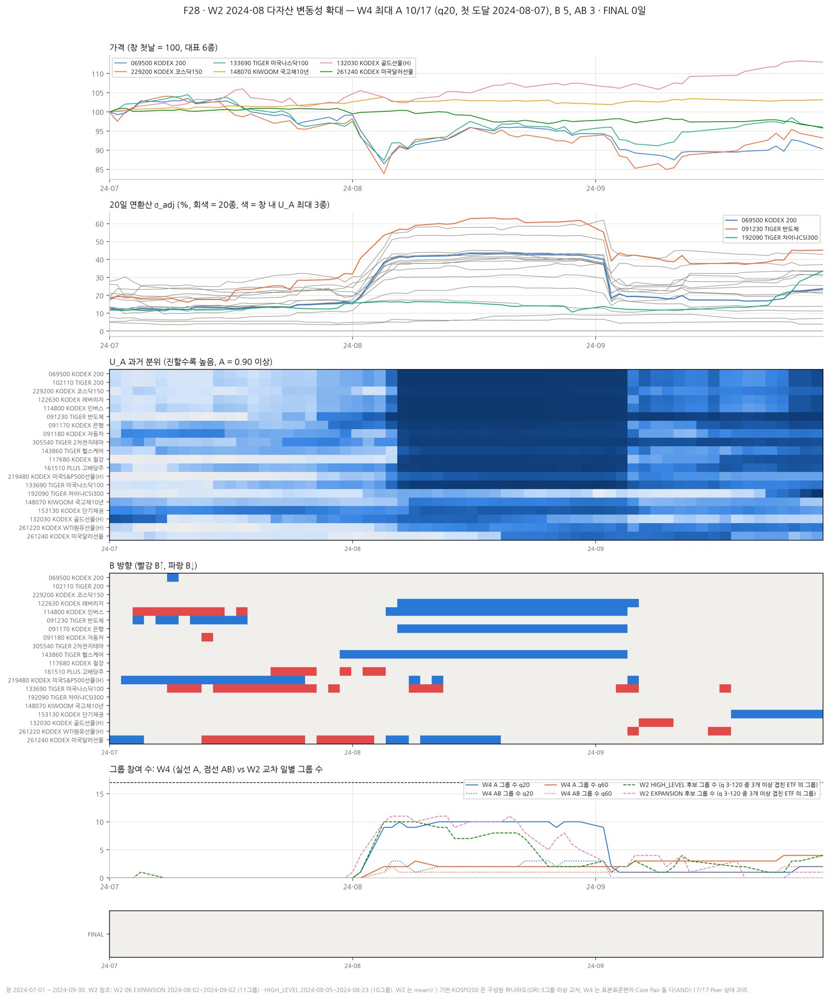

{"q20": {"max_n_A": 10, "max_n_B": 5, "max_n_AB": 3, "max_n_A_date": "2024-08-07", "final_days": 0}, "q60": {"max_n_A": 4, "max_n_B": 7, "max_n_AB": 2, "max_n_A_date": "2024-09-25", "final_days": 0}}


In [40]:
CAP["F28_event_E2024_08"] = FG.f_event("E2024_08", "28", "W2 2024-08 다자산 변동성 확대")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F28_event_E2024_08.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F28_event_E2024_08"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

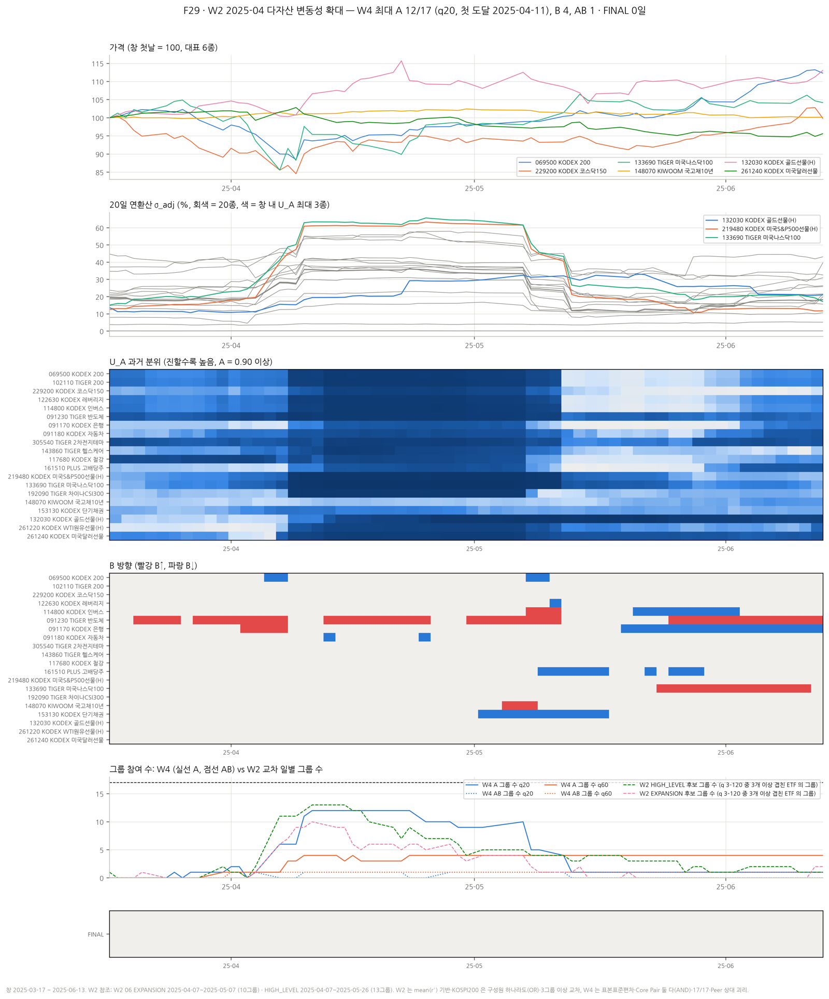

{"q20": {"max_n_A": 12, "max_n_B": 4, "max_n_AB": 1, "max_n_A_date": "2025-04-11", "final_days": 0}, "q60": {"max_n_A": 4, "max_n_B": 3, "max_n_AB": 1, "max_n_A_date": "2025-04-10", "final_days": 0}}


In [41]:
CAP["F29_event_E2025_04"] = FG.f_event("E2025_04", "29", "W2 2025-04 다자산 변동성 확대")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F29_event_E2025_04.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F29_event_E2025_04"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

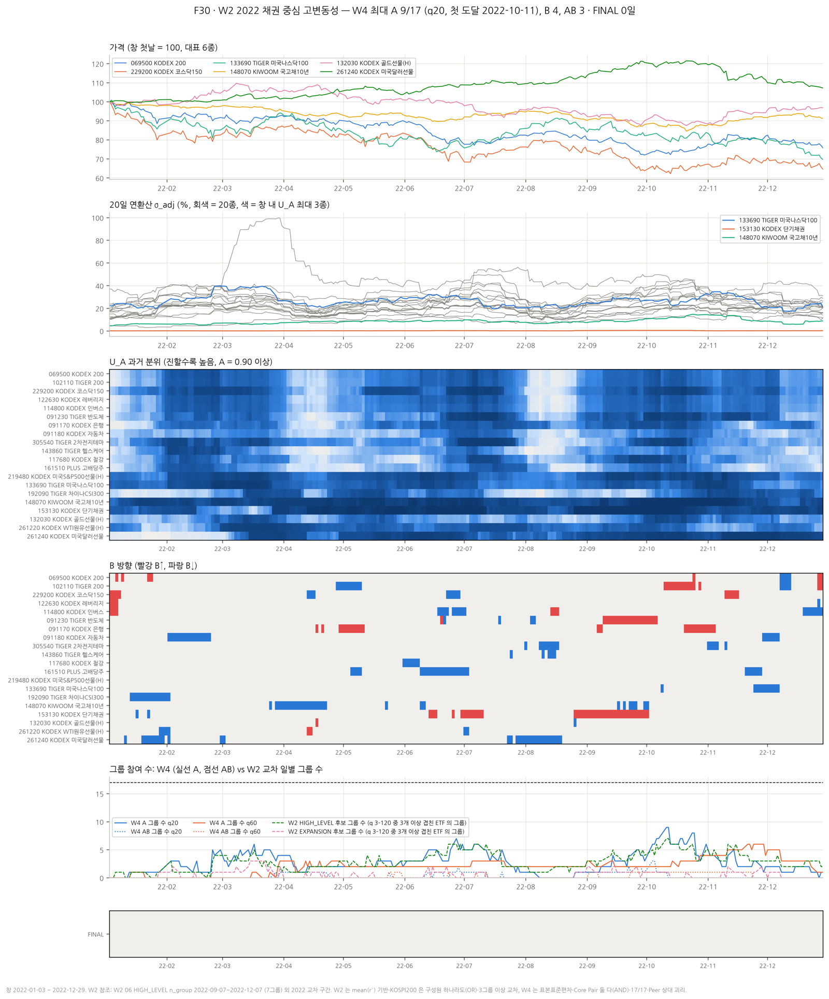

{"q20": {"max_n_A": 9, "max_n_B": 4, "max_n_AB": 3, "max_n_A_date": "2022-10-11", "final_days": 0}, "q60": {"max_n_A": 6, "max_n_B": 3, "max_n_AB": 1, "max_n_A_date": "2022-11-21", "final_days": 0}}


In [42]:
CAP["F30_event_E2022_bond"] = FG.f_event("E2022_bond", "30", "W2 2022 채권 중심 고변동성")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F30_event_E2022_bond.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F30_event_E2022_bond"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

In [43]:
# 사건별 전체 요약 (최대 참여·FINAL) 과 ETF 별 A·B·W2 신호 일수.
EV = pd.read_csv(RES / "event_case_studies.csv", dtype={"ticker": str})  # 사건 표
display(EV[EV["level"] == "global"].dropna(axis=1, how="all"))  # 사건별 전체 요약
e20 = EV[(EV["level"] == "etf") & (EV["q"] == 20)]  # ETF 단위 q=20
display(e20.groupby("event")[["A_days", "B_UP_days", "B_DOWN_days", "AB_days", "w2_high_days", "w2_expansion_days"]].apply(lambda d: (d > 0).sum()))  # 신호가 한 번이라도 나온 ETF 수

,event,level,ticker,group,q,A_days,AB_days,days,max_n_A,max_n_B,max_n_AB,max_n_A_date,final_days
20,E2022_bond,global,__ALL__,__17__,20,0,0,246,9.0,4.0,3.0,2022-10-11,0.0
41,E2022_bond,global,__ALL__,__17__,60,0,0,246,6.0,3.0,1.0,2022-11-21,0.0
62,E2024_08,global,__ALL__,__17__,20,0,0,62,10.0,5.0,3.0,2024-08-07,0.0
83,E2024_08,global,__ALL__,__17__,60,0,0,62,4.0,7.0,2.0,2024-09-25,0.0
104,E2025_04,global,__ALL__,__17__,20,0,0,60,12.0,4.0,1.0,2025-04-11,0.0
125,E2025_04,global,__ALL__,__17__,60,0,0,60,4.0,3.0,1.0,2025-04-10,0.0


,A_days,B_UP_days,B_DOWN_days,AB_days,w2_high_days,w2_expansion_days
event,,,,,,
E2022_bond,13,10,18,4,14,20
E2024_08,14,7,9,5,14,19
E2025_04,15,5,7,3,15,16


**해석 (F28–F30).**

| 사건 | W4 최대 (q=20) | W2 | 차이 |
|---|---|---|---|
| 2024-08 | A 10/17 (첫 도달 2024-08-07) · B 5 · AB 3 | EXPANSION 11그룹 · HIGH_LEVEL 10그룹 | A 의 폭은 W2 와 비슷하다. B 는 **B↓**(143860·114800·122630·091170·219480, 각 19–25일)가 주이고, B↑ 는 133690 19일이다 |
| 2025-04 | A 12/17 (2025-04-11~04-23, 9일) · B 4 · AB 1 | HIGH_LEVEL 13그룹 | 주분석 최대 A 참여일. 그러나 B 는 최대 4 그룹, AB 는 1 그룹이다 |
| 2022 채권 | A 9/17 (첫 도달 2022-10-11) · B 4 · AB 3 | HIGH_LEVEL 2022-09-07~12-07 7그룹 | AB 는 153130 38일(B↑)·148070 28일(B↓)·091230 6일·229200 5일. W2 처럼 KOSPI200 그룹 A 는 0일이다 |

세 사건 모두 FINAL 은 0일이다.

W2 와 W4 의 차이는 두 층으로 나뉜다.
- **계산 정의**: σ(평균 차감·ddof 1) 대 √(252·mean r²). 순위가 거의 같다 (§14).
- **구간 정의**: W2 는 3그룹 이상 + KOSPI200 은 구성원 하나라도(OR) 이고, W4 는 17/17 + Core Pair 둘 다(AND) + 상대 괴리 B 다. 차이는 대부분 이쪽에서 생긴다.

## 14. 기존 W2·W3 와 비교

In [44]:
# W2 정의 재계산이 W2 공개 결과(signal_rates.csv, q=20·60 HIGH_LEVEL·EXPANSION)와 정확히 같은지 확인한다.
W2C = pd.read_csv(BASE / "evidence/w2_reconstruction_check.csv", dtype={"ticker": str})  # 재계산 대조표
print("W2 재계산 일치:", int(W2C["match"].sum()), "/", len(W2C))  # 80/80 이어야 함
assert W2C["match"].all()  # 하나라도 다르면 W2 대조를 쓰지 않는다
CMP = pd.read_csv(RES / "comparison_w2_w3.csv", dtype={"ticker": str})  # 대조표
cd = CMP[CMP["block"] == "calc_definition"]  # 계산 정의 차이
display(cd.groupby("q")[["sigma_vs_rv_spearman", "sigma_over_rv_median", "jaccard_A_vs_w2_high", "agreement_rate"]].agg(["min", "median", "max"]).round(3))  # 요약
display(CMP[CMP["block"] == "interval_definition"].dropna(axis=1, how="all"))  # 구간 정의 차이

W2 재계산 일치: 80 / 80


sigma_vs_rv_spearman               sigma_over_rv_median               jaccard_A_vs_w2_high             agreement_rate            
                    min median    max                  min median    max                  min median  max            min median  max
q                                                                                                                                   
20                0.869  0.992  0.996                0.783  1.014  1.017                0.531  0.868  1.0          0.929  0.989  1.0
60                0.932  0.997  1.000                0.872  1.004  1.006                0.812  0.948  1.0          0.946  0.998  1.0

,block,ticker,q,w2_days_ge3_groups,w2_max_groups,w4_days_A_17,w4_days_AB_17,w4_max_n_A,w4_max_n_AB,spearman_w2_n_vs_w4_n_A
40,interval_definition,W2_HIGH_LEVEL_n_group,20,338.0,13.0,0.0,0.0,12.0,3.0,0.814530
41,interval_definition,W2_HIGH_LEVEL_n_group,60,338.0,13.0,0.0,0.0,6.0,2.0,0.578580
42,interval_definition,W2_EXPANSION_n_group,20,112.0,11.0,0.0,0.0,12.0,3.0,0.420058
43,interval_definition,W2_EXPANSION_n_group,60,112.0,11.0,0.0,0.0,6.0,2.0,0.256872


**해석 (계산 정의 vs 구간 정의).**
- 같은 원자료에서 W2 정의를 다시 계산했다. W2 공개표와 **80/80** 일치한다 (q=20·60 × HIGH_LEVEL·EXPANSION × 20종의 추정 가능일·신호일).
- **계산 정의 차이**
  - σ 와 √(252·mean r²) 의 Spearman 중앙값은 q20 0.992, q60 0.997 이다.
  - A 와 W2 HIGH_LEVEL 의 일치율 중앙값은 0.989 / 0.998 이다.
  - 가장 낮은 Jaccard 는 143860 q20 의 0.531 이다 (A 48일 대 W2 27일).
- **구간 정의 차이**
  - 주분석에서 W2 HIGH_LEVEL 3그룹 이상인 날은 338일, 최대 13그룹이다.
  - 같은 기간 W4 A 17/17 은 0일, 최대 12그룹이다.
  - 따라서 W4 에서 구간이 0개인 이유는 계산 정의가 아니라 17/17 과 B 요구에 있다.

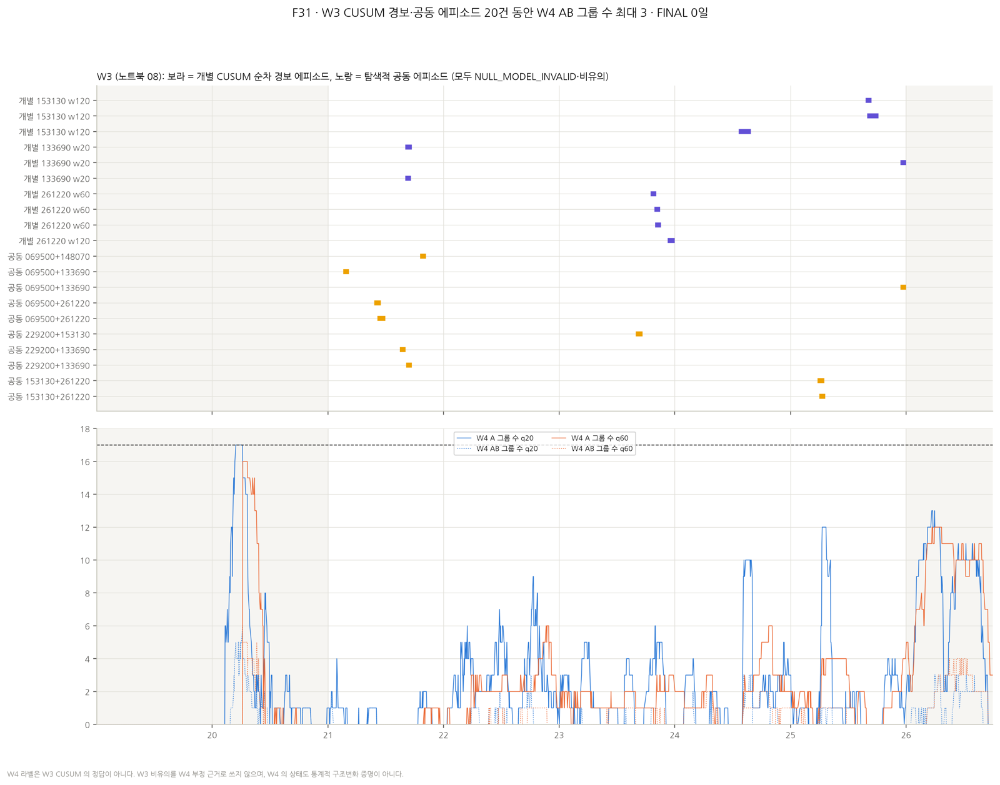

{"w3_episodes": 20, "w4_max_n_AB_during_w3": 3, "w4_final_days_during_w3": 0}


In [45]:
CAP["F31_w3_comparison"] = FG.f31_w3()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F31_w3_comparison.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F31_w3_comparison"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (F31).**
- W3 의 개별 CUSUM 순차 경보 에피소드(10건)와 탐색적 공동 에피소드(10건)는 모두 `NULL_MODEL_INVALID`·비유의다.
- 이 20건 동안 W4 AB 참여는 최대 3 그룹이고, FINAL 은 0일이다.
- 두 결과가 '일치' 한다고 읽지 않는다.
  - W3 비유의는 검출력 부족 때문이다. 시장이 안정적이었다는 증거가 아니다.
  - W4 0개는 정의가 엄격하기 때문이다. 급변이 없었다는 증거가 아니다.

## 15. 반례·민감도·검증

In [46]:
# 민감도 (주 정의를 대체하지 않음): 504일 고정 기준 · A 0.95 · B 2.5% · KOSPI200 4종.
SENS = pd.read_csv(RES / "sensitivity_summary.csv")  # 민감도 요약
display(SENS.filter(regex="variant|verdict|n_intervals|max_n|days17|days16plus|days15plus"))  # 핵심 열
TP = pd.read_csv(RES / "threshold_proximity.csv")  # 임계값 ±0.01 안 비율
display(TP)  # 임계값 인근 안정성
assert (SENS["n_intervals"] == 0).all()  # 어느 민감도에서도 구간 0

,variant,verdict,n_intervals,q20_max_n_A,q20_days17_A,q20_max_n_B,q20_days17_B,q20_max_n_AB,q20_days17_AB,q20_days16plus_AB,q20_days15plus_AB,q60_max_n_A,q60_days17_A,q60_max_n_B,q60_days17_B,q60_max_n_AB,q60_days17_AB,q60_days16plus_AB,q60_days15plus_AB
0,MAIN,VALID_ZERO_INTERVALS,0,12,0,7,0,3,0,0,0,6,0,7,0,2,0,0,0
1,FIXED_504,VALID_ZERO_INTERVALS,0,11,0,8,0,4,0,0,0,9,0,8,0,4,0,0,0
2,A_095,VALID_ZERO_INTERVALS,0,8,0,7,0,3,0,0,0,3,0,7,0,1,0,0,0
3,B_2.5,VALID_ZERO_INTERVALS,0,12,0,6,0,2,0,0,0,6,0,6,0,2,0,0,0
4,K200_FOUR,VALID_ZERO_INTERVALS,0,12,0,7,0,4,0,0,0,6,0,7,0,2,0,0,0


,q,A_near_share,B_up_near_share,B_down_near_share,band
0,20,0.024694,0.015878,0.016000,0.01
1,60,0.022408,0.017551,0.020571,0.01


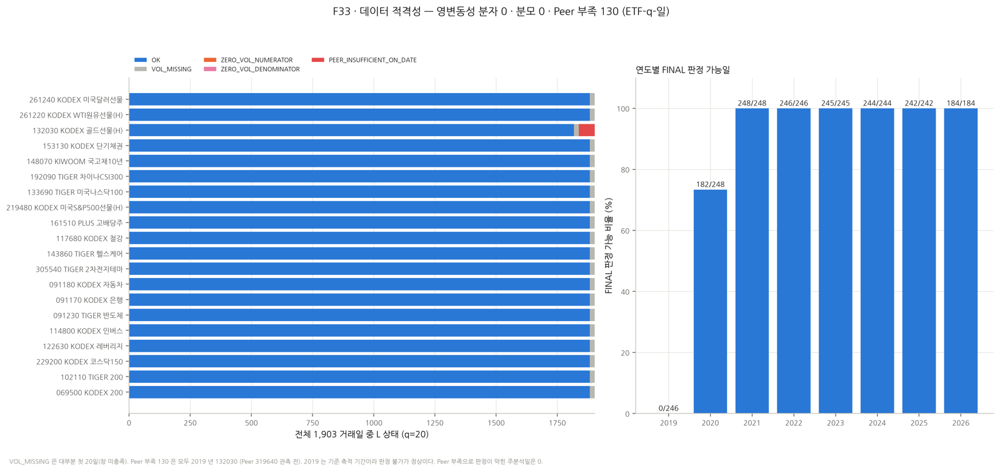

{"zero_num_total": 0, "zero_den_total": 0, "peer_insufficient_total": 130}


In [47]:
CAP["F33_eligibility"] = FG.f33_eligibility()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F33_eligibility.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F33_eligibility"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**해석 (민감도·적격성).**
- 민감도 4종 모두 17/17 AB 는 0일이고 구간도 0개다.
- AB 최대 참여: 504일 기준 4 · A 0.95 기준 3 · B 2.5% 기준 2 · KOSPI200 4종 4.
- 16/17·15/17 AB 인 날도 모든 설정에서 0일이다.
- 임계값 ±0.01 안에 있는 ETF-일은 A 2.2–2.5%, B 1.6–2.1% 다. 임계값을 조금 움직여도 17/17 까지의 거리(최소 14 그룹 부족)를 메우지 못한다.
- 적격성
  - 영변동성(분자·분모)은 0건이다.
  - Peer 부족은 130 ETF-q-일로, 전부 2019 년 132030 의 Peer(319640) 관측 이전이다.
  - 주분석 FINAL 판정 가능일은 100% 다.

## 16. 결론과 다음 연구의 조건

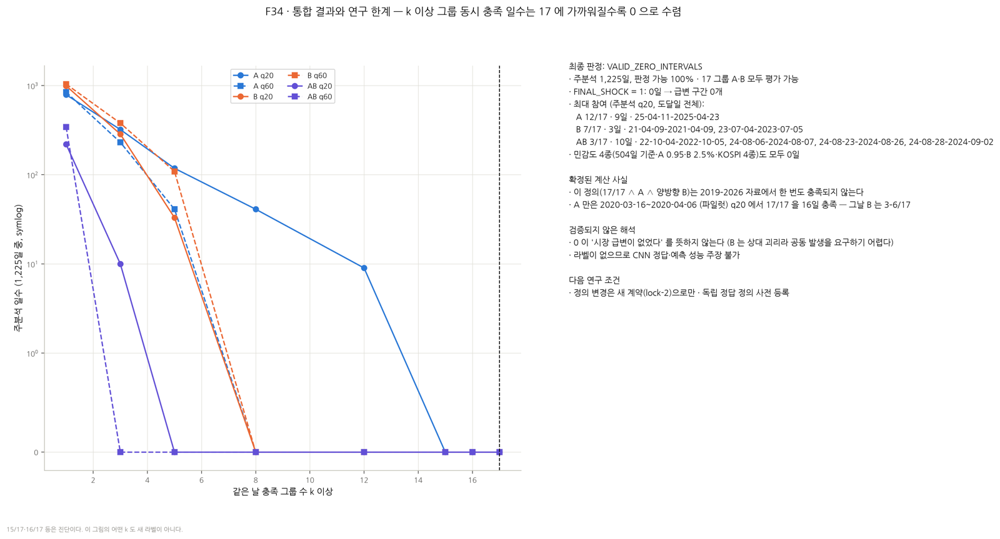

{"verdict": "VALID_ZERO_INTERVALS"}


In [48]:
CAP["F34_summary_limits"] = FG.f34_summary()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
display(Image(data=preview(FIGDIR / "F34_summary_limits.png")))  # 저장된 PNG(320dpi)의 축소 미리보기 표시
print(json.dumps(CAP["F34_summary_limits"], ensure_ascii=False, default=str)[:900])  # 그림 캡션의 실제 수치

**최종 판정: `VALID_ZERO_INTERVALS`.** 평가 가능일은 충분하다. 그러나 사전 정의(17/17 ∧ A ∧ 양방향 B, 20일 ∨ 60일)를 충족한 급변 구간은 0개다.

| 질문 | 답 |
|---|---|
| 20개 ETF 의 σ 는 언제 자기 과거 대비 높아지는가 | 2020-03 에는 전부 함께 높아졌다. 주분석 최대는 2025-04-11~04-23 (12/17) 이고, 사건 창 최대는 2024-08 (10/17)·2022 하반기 (9/17) 다 |
| 어떤 ETF 가 Peer 와의 관계에서 벗어나는가 | Tier 2 매핑(117680·153130·091180·161510)에서 B 가 잦다. 동일 지수 쌍에서도 생긴다 |
| 방향 | 하방(B↓)이 상방보다 많다 (q20 1,260 대 1,022 ETF-일) |
| A 와 B 는 같은 날인가 | 대체로 아니다 (A 의 12.6–22.1% 만 겹친다) |
| KOSPI200 동일 지수 사이 괴리 | 있다 (|L| 중앙 0.894 %p, 꼬리 이탈 158일) |
| 레버리지·인버스 정규화 | σ 비율 중앙 1.004·1.025, A 일치 98.9% 이상 |
| 최대 동시 충족 | A 12 · B 7 · AB 3 (주분석) |
| 17/17 GLOBAL_AB | **관찰되지 않음** (전체 기간 포함) |
| 병목 | B 의 공동 발생 부족이 주 원인이다 (A 가 17/17 인 날에도 B ≤ 6). 단일 그룹 병목은 없다 |
| 20 대 60 | 그룹-일 Jaccard A 0.30, AB 0.17 |
| W2 사건 분류 | 세 사건 모두 FINAL 0. A 폭은 W2 와 비슷하지만 B 가 없다 |
| W3 와의 관계 | W3 에피소드 20건 동안 AB 최대 3. 서로의 정답이 아니다 |

**확정된 계산 사실과 검증되지 않은 해석.**
- 확정: 위 수치 전부. 동결 규칙·같은 원자료에서 재현된다.
- 미검증: '0 = 급변 없음' 은 성립하지 않는다. B 는 상대 괴리라 여러 자산에서 함께 나타나기 어렵다. 이 정의가 시장 급변을 잡는 데 적합한지는 별도 문제다.

**다음 연구의 조건.**
- 이 결과로는 CNN 에 넘길 급변 구간이 없다.
- 정의를 바꾸려면 결과를 본 뒤의 사후 완화가 아니라 **새 계약(lock-2)** 이어야 한다. 이번 결과를 본 상태라는 사실도 계약에 적는다.
- 급등 탐지 연구에 라벨을 쓰려면 다음 두 가지를 먼저 사전 등록해야 한다.
  - 가격에서 독립적으로 정한 정답(예: 미래 h일 수익률 꼬리)
  - 2026 이후 독립 자료

## 17. 수치 대조 (CLAIMS) — 해석 문단의 숫자를 결과표로 다시 확인

In [49]:
# 해석에 쓴 숫자를 결과 파일에서 다시 읽어 대조한다 (불일치면 실패).
gl = pd.read_csv(RES / "global_daily_counts.csv")  # 일별 그룹 수
pr = gl[gl["period"] == "PRIMARY"]  # 주분석
CLAIMS = [  # (주장, 관측, 기대)
    ("판정", V["verdict"], "VALID_ZERO_INTERVALS"),  # 최종 판정
    ("주분석 일수", V["primary_days"], 1225),  # 기대값 2021–2025
    ("판정 가능 비율", V["primary_evaluable_share"], 1.0),  # 기대값 100%
    ("FINAL 1 일수", V["primary_final_true_days"], 0),  # 0일
    ("구간 수", len(IV), 0),  # 0개
    ("q20 최대 A", int(pr[pr.q == 20].n_A.max()), 12),  # 기대값 12/17
    ("q60 최대 A", int(pr[pr.q == 60].n_A.max()), 6),  # 기대값 6/17
    ("최대 B", int(pr.n_B.max()), 7),  # 기대값 7/17
    ("q20 최대 AB", int(pr[pr.q == 20].n_AB.max()), 3),  # 기대값 3/17
    ("q20 AB 3 도달 구간", MPD[(MPD.q == 20) & (MPD.state == "AB")].spans.iloc[0], "2022-10-04~2022-10-05;2024-08-06~2024-08-07;2024-08-23~2024-08-26;2024-08-28~2024-09-02"),  # 도달일 전체
    ("q20 A 12 도달 구간", MPD[(MPD.q == 20) & (MPD.state == "A")].spans.iloc[0], "2025-04-11~2025-04-23"),  # 도달일 전체
    ("q60 A 6 도달 일수", int(MPD[(MPD.q == 60) & (MPD.state == "A")].n_days_at_max.iloc[0]), 14),  # 2022-11 과 2024-10~11  # 기대값 3/17
    ("q60 최대 AB", int(pr[pr.q == 60].n_AB.max()), 2),  # 기대값 2/17
    ("파일럿 A 17/17 일수", int(GBP[(GBP.period == "PILOT") & (GBP.q == 20)].days17_A.iloc[0]), 16),  # 기대값 2020-03-16~04-06
    ("파일럿 A 17/17 첫날", str(gl[(gl.q == 20) & (gl.GLOBAL_A == 1)].date.min()), "2020-03-16"),  # 시작
    ("파일럿 A 17/17 마지막날", str(gl[(gl.q == 20) & (gl.GLOBAL_A == 1)].date.max()), "2020-04-06"),  # 끝
    ("파일럿 A 17/17 날 최대 B", int(gl[(gl.q == 20) & (gl.GLOBAL_A == 1)].n_B.max()), 6),  # 기대값 B ≤ 6
    ("A∩B 비율 q20", CAP["F19_A_B_intersection"]["q20"]["AB_share_of_A"], 0.1261),  # 기대값 12.6%
    ("A∩B 비율 q60", CAP["F19_A_B_intersection"]["q60"]["AB_share_of_A"], 0.2215),  # 기대값 22.1%
    ("B↑ q20", CAP["F09_B_direction_map"]["q20"]["up"], 1022),  # 상방
    ("B↓ q20", CAP["F09_B_direction_map"]["q20"]["down"], 1260),  # 하방
    ("Core |L| 중앙 %p", CAP["F10_kospi200_four"]["core_L_abs_median_pctpt"], 0.894),  # 기대값 KOSPI200
    ("Core B 일수", CAP["F10_kospi200_four"]["core_B_UP"] + CAP["F10_kospi200_four"]["core_B_DOWN"], 158),  # 기대값 87+71
    ("Peer 수", CAP["F06_peer_network"]["n_peers"], 42),  # 참조 42종
    ("W2 재계산 일치", int(W2C["match"].sum()), 80),  # 기대값 80/80
    ("W3 에피소드 수", CAP["F31_w3_comparison"]["w3_episodes"], 20),  # 기대값 10+10
    ("W3 중 AB 최대", CAP["F31_w3_comparison"]["w4_max_n_AB_during_w3"], 3),  # 기대값 3
    ("2024-08 A 최대", CAP["F28_event_E2024_08"]["q20"]["max_n_A"], 10),  # 사건
    ("2025-04 A 최대", CAP["F29_event_E2025_04"]["q20"]["max_n_A"], 12),  # 사건
    ("2022 A 최대", CAP["F30_event_E2022_bond"]["q20"]["max_n_A"], 9),  # 사건
    ("한 그룹 제외 16/16 AB 최대", CAP["F26_bottleneck"]["q20"]["loo_AB_max"], 0),  # 병목 진단
    ("Jaccard 20·60 A", CAP["F20_horizon_20_vs_60"]["jaccard_group_day_A"], 0.3033),  # 기간 일치
    ("민감도 구간 수 합", int(SENS["n_intervals"].sum()), 0),  # 모두 0
]  # 끝
bad = {k: (o, x) for k, o, x in CLAIMS if (round(o, 4) if isinstance(o, float) else o) != x}  # 불일치 주장
print(f"CLAIMS {len(CLAIMS) - len(bad)}/{len(CLAIMS)} 일치")  # 결과
assert not bad, bad  # 불일치가 있으면 해석 문단을 고쳐야 한다

CLAIMS 33/33 일치


In [50]:
# 결과 파일 지문을 남긴다 (두 번 실행 시 바이트 동일 여부는 evidence/reproducibility_report.md).
DIG = P.results_digest(ROOT)  # results/ 아래 파일 SHA256
print(len(DIG), "개 결과 파일 ·", len(list(FIGDIR.glob("*.png"))), "PNG ·", len(list(FIGDIR.glob("*.svg"))), "SVG")  # 산출물 수
(BASE / "results/figure_captions.json").write_text(json.dumps(CAP, ensure_ascii=False, indent=1, default=str, sort_keys=True) + "\n", encoding="utf-8")  # 캡션 수치 저장

23 개 결과 파일 · 34 PNG · 34 SVG


9900